In [1]:
## Import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

# Pour l'autocorrélation
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import pearsonr

warnings.filterwarnings('ignore')



## Etapes

2. Analyse univariée

* Distributions : Histogrammes de chaque polluant et variable météo
* Outliers : Box plots pour identifier les valeurs aberrantes
* Statistiques descriptives : Médiane, quartiles, asymétrie

3. Analyse temporelle

* Tendances : Évolution des polluants dans le temps
* Saisonnalité : Variations selon les mois/saisons
* Cycles quotidiens : Patterns horaires si tu as cette granularité
* Corrélations temporelles : Autocorrélations

4. Relations entre variables

* Matrice de corrélation : Entre tous les polluants et conditions météo
* Scatter plots : Relations polluants vs météo
* Comparaison capteurs : GT vs PT08 pour chaque polluant

5. Patterns spécifiques qualité de l'air

* Pollution vs météo : Impact température/humidité sur concentrations
* Co-occurrences : Quels polluants augmentent ensemble
* Épisodes de pollution : Identification des pics

6. Visualisations clés

* Heatmap de corrélations
* Time series des principaux polluants
* Distribution des concentrations par saison

In [2]:
data = pd.read_csv('AirQualityUCI_cleaned.csv')
data

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,DateTime
0,1.620511,1545.0,176.904406,22.1,1353.0,245.757321,767.0,112.291221,2058.0,1588.0,9.2,56.2,0.6561,2004-03-12 09:00:00
1,2.800000,1473.0,176.904406,14.3,1127.0,224.000000,831.0,152.000000,1752.0,1568.0,20.8,34.4,0.8365,2004-03-18 11:00:00
2,2.200000,1379.0,176.904406,12.5,1068.0,171.000000,899.0,139.000000,1663.0,1374.0,23.8,28.2,0.8219,2004-03-18 12:00:00
3,2.200000,1385.0,176.904406,12.2,1056.0,149.000000,891.0,133.000000,1648.0,1268.0,24.2,28.7,0.8515,2004-03-18 13:00:00
4,2.300000,1379.0,176.904406,13.1,1087.0,137.000000,901.0,126.000000,1660.0,1144.0,25.2,24.9,0.7829,2004-03-18 14:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6790,1.100000,1031.0,176.904406,4.4,730.0,182.000000,760.0,93.000000,1129.0,905.0,9.5,63.1,0.7531,2005-04-04 06:00:00
6791,2.400000,1163.0,176.904406,11.4,1027.0,353.000000,604.0,179.000000,1264.0,1269.0,24.3,23.7,0.7119,2005-04-04 11:00:00
6792,2.400000,1142.0,176.904406,12.4,1063.0,293.000000,603.0,175.000000,1241.0,1092.0,26.9,18.3,0.6406,2005-04-04 12:00:00
6793,2.100000,1003.0,176.904406,9.5,961.0,235.000000,702.0,156.000000,1041.0,770.0,28.3,13.5,0.5139,2005-04-04 13:00:00


## Etape1: Analyse univariée

ANALYSE UNIVARIÉE

📊 INFORMATIONS GÉNÉRALES:
• Nombre de lignes: 6,795
• Nombre de colonnes: 14
• Période: 2004-03-12 09:00:00 à 2005-04-04 14:00:00
• Polluants (GT + capteurs): 10
• Variables météo: 3

📈 STATISTIQUES DESCRIPTIVES DÉTAILLÉES:
--------------------------------------------------
         Variable  Count  Missing      Mean    Median      Std      Min  \
0          CO(GT)   6795        0     1.672     1.621    0.798    0.100   
1     PT08.S1(CO)   6795        0  1043.808  1031.000  154.447  667.000   
2        NMHC(GT)   6795        0   176.904   176.904    0.000  176.904   
3        C6H6(GT)   6795        0     8.323     7.500    5.009    0.500   
4   PT08.S2(NMHC)   6795        0   884.615   877.000  201.379  440.000   
5         NOx(GT)   6795        0   196.605   205.000  105.827   14.000   
6    PT08.S3(NOx)   6795        0   843.541   834.000  181.528  434.000   
7         NO2(GT)   6795        0   103.964   112.291   32.157   23.000   
8    PT08.S4(NO2)   6795       

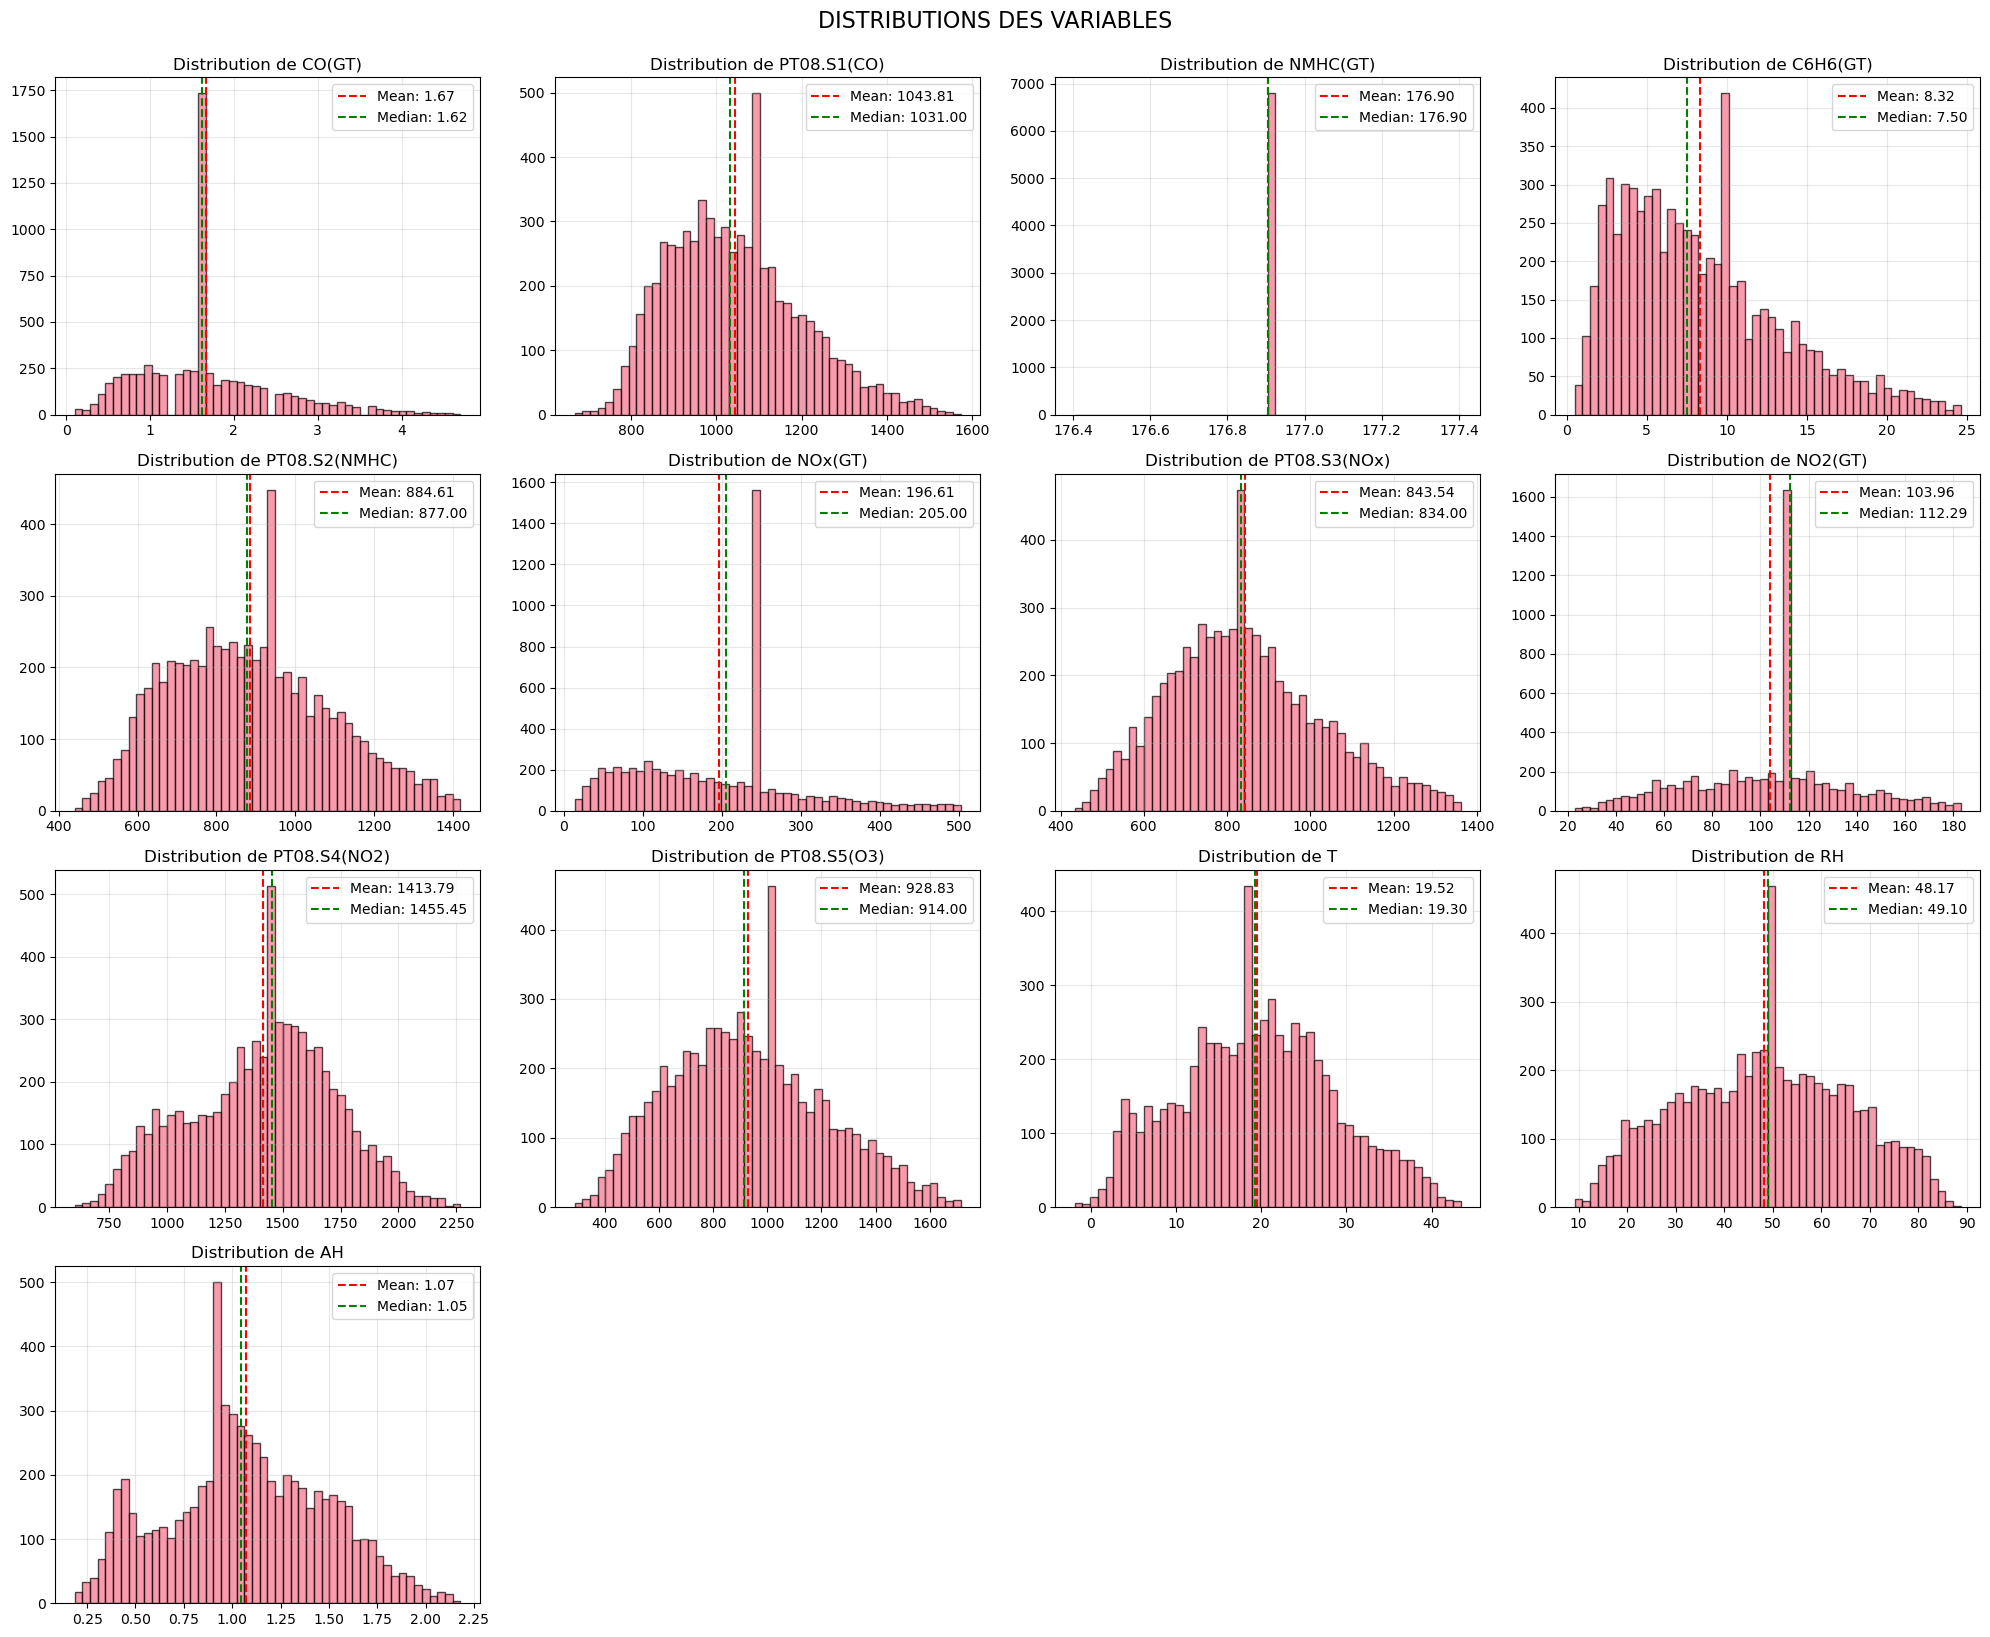

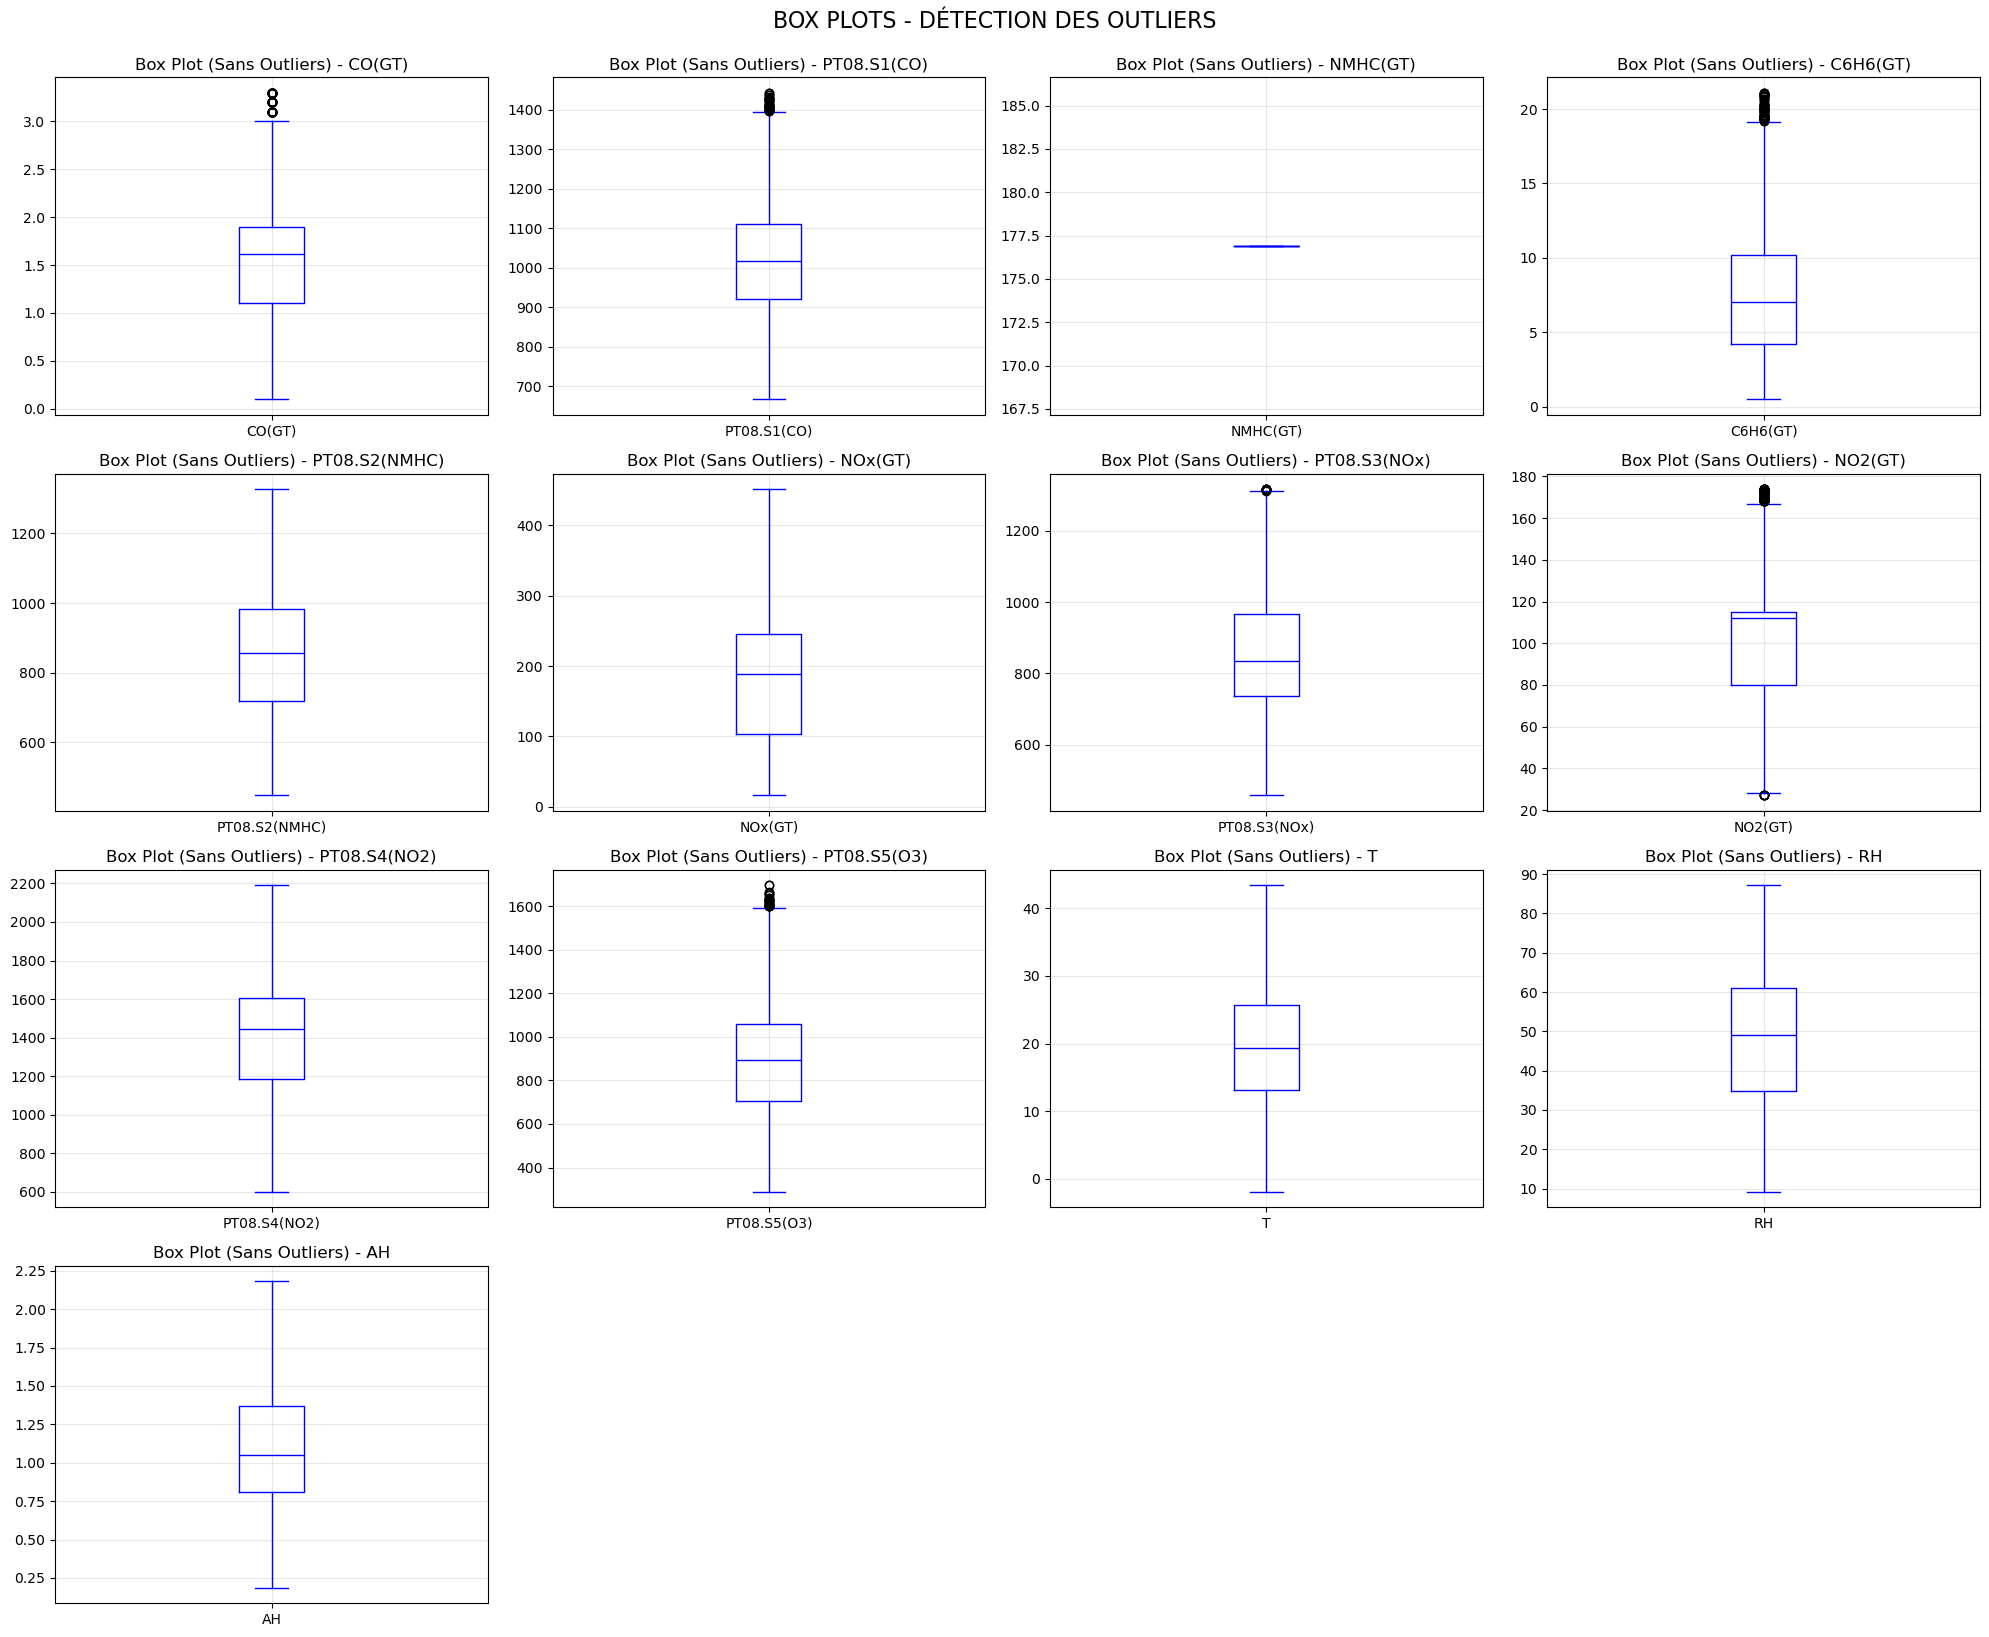

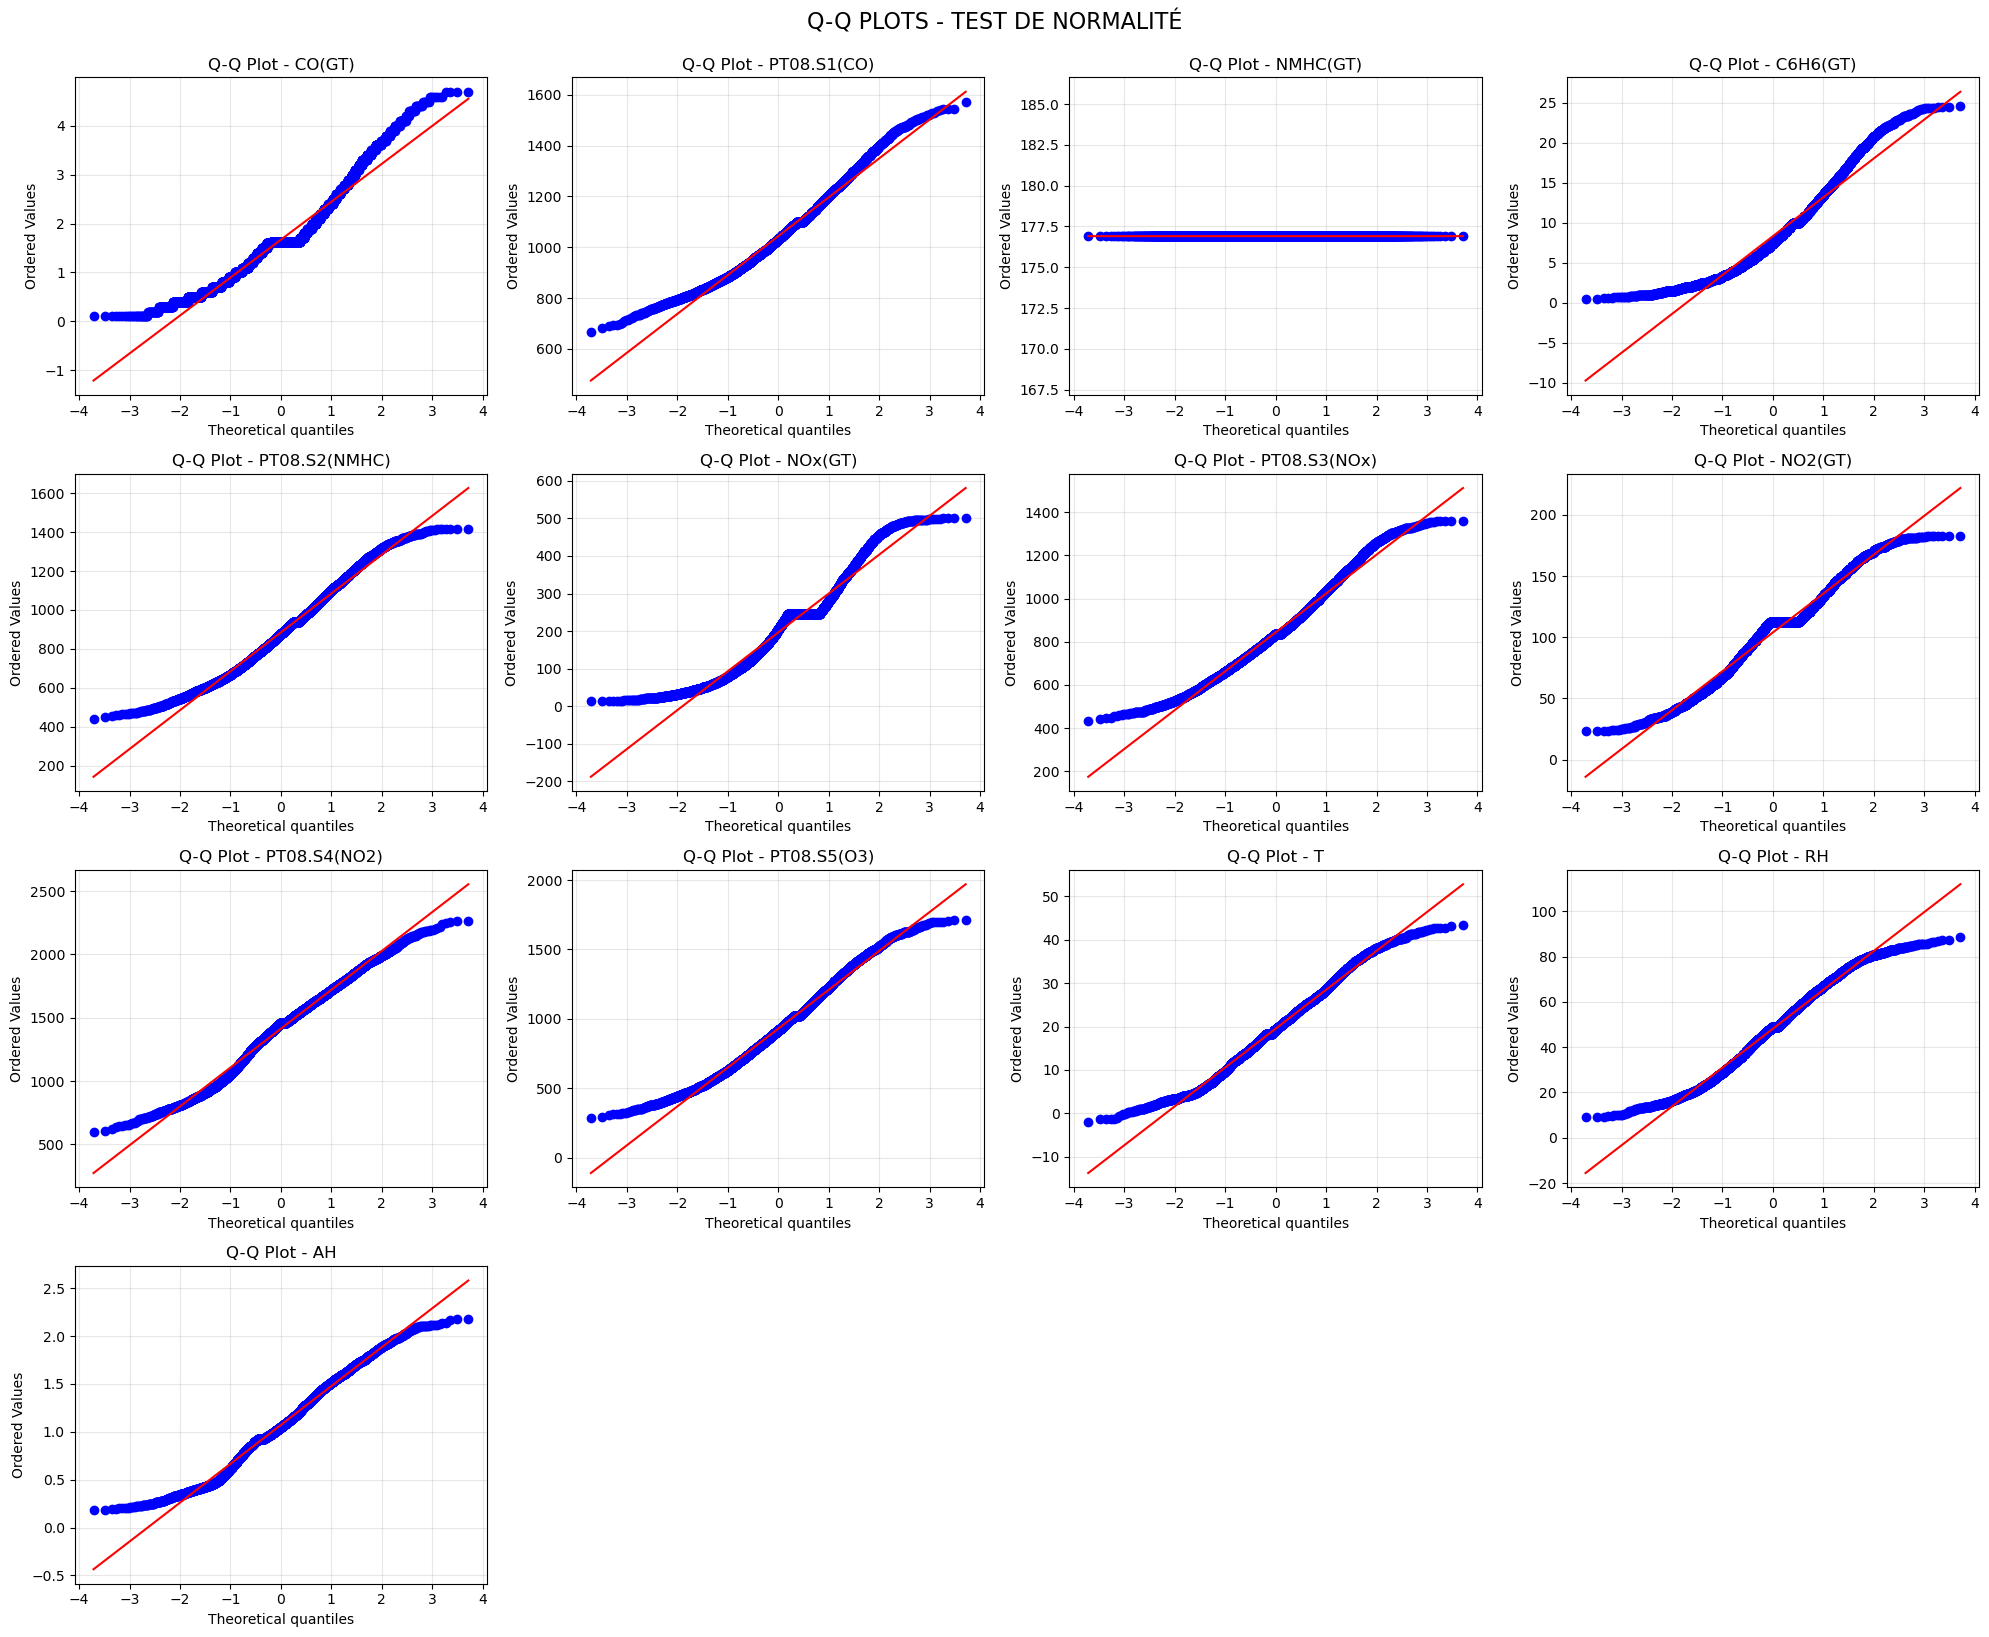


🏭 ANALYSE PAR CATÉGORIE DE VARIABLES:
--------------------------------------------------

📍 POLLUANTS - MESURES DE RÉFÉRENCE (GT):
• CO(GT): Moy=1.67, Médiane=1.62, Écart-type=0.80
• NMHC(GT): Moy=176.90, Médiane=176.90, Écart-type=0.00
• C6H6(GT): Moy=8.32, Médiane=7.50, Écart-type=5.01
• NOx(GT): Moy=196.61, Médiane=205.00, Écart-type=105.83
• NO2(GT): Moy=103.96, Médiane=112.29, Écart-type=32.16

🔧 CAPTEURS SEMI-CONDUCTEURS (PT08):
• PT08.S1(CO): Moy=1043.81, Médiane=1031.00, Écart-type=154.45
• PT08.S2(NMHC): Moy=884.61, Médiane=877.00, Écart-type=201.38
• PT08.S3(NOx): Moy=843.54, Médiane=834.00, Écart-type=181.53
• PT08.S4(NO2): Moy=1413.79, Médiane=1455.45, Écart-type=308.75
• PT08.S5(O3): Moy=928.83, Médiane=914.00, Écart-type=281.77

🌤️ VARIABLES MÉTÉOROLOGIQUES:
• T: Moy=19.52, Médiane=19.30, Écart-type=9.00
• RH: Moy=48.17, Médiane=49.10, Écart-type=17.28
• AH: Moy=1.07, Médiane=1.05, Écart-type=0.41

📐 TESTS DE NORMALITÉ (Shapiro-Wilk sur échantillon):
--------------------

In [3]:


# Configuration des graphiques
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)

# Supposons que ton dataset s'appelle 'data'
# data = pd.read_csv('ton_fichier.csv')

def analyze_univariate(data):
    # 1. VUE D'ENSEMBLE DES DONNÉES
    print("="*60)
    print("ANALYSE UNIVARIÉE")
    print("="*60)
    
    print("\n📊 INFORMATIONS GÉNÉRALES:")
    print(f"• Nombre de lignes: {len(data):,}")
    print(f"• Nombre de colonnes: {len(data.columns)}")
    print(f"• Période: {data['DateTime'].min()} à {data['DateTime'].max()}")
    
    # Séparer les colonnes par type
    pollutant_cols = [col for col in data.columns if 'GT' in col or 'PT08' in col]
    weather_cols = ['T', 'RH', 'AH']
    
    print(f"• Polluants (GT + capteurs): {len(pollutant_cols)}")
    print(f"• Variables météo: {len(weather_cols)}")
    
    # 2. STATISTIQUES DESCRIPTIVES DÉTAILLÉES
    print("\n📈 STATISTIQUES DESCRIPTIVES DÉTAILLÉES:")
    print("-" * 50)
    
    # Pour chaque variable numérique
    numeric_cols = data.select_dtypes(include=[np.number]).columns
    
    stats_summary = []
    for col in numeric_cols:
        col_data = data[col].dropna()
        
        stats_dict = {
            'Variable': col,
            'Count': len(col_data),
            'Missing': data[col].isnull().sum(),
            'Mean': col_data.mean(),
            'Median': col_data.median(),
            'Std': col_data.std(),
            'Min': col_data.min(),
            'Max': col_data.max(),
            'Q1': col_data.quantile(0.25),
            'Q3': col_data.quantile(0.75),
            'IQR': col_data.quantile(0.75) - col_data.quantile(0.25),
            'Skewness': stats.skew(col_data),
            'Kurtosis': stats.kurtosis(col_data),
            'Outliers_IQR': len(col_data[(col_data < (col_data.quantile(0.25) - 1.5 * (col_data.quantile(0.75) - col_data.quantile(0.25)))) | 
                                      (col_data > (col_data.quantile(0.75) + 1.5 * (col_data.quantile(0.75) - col_data.quantile(0.25))))])
        }
        stats_summary.append(stats_dict)
    
    stats_df = pd.DataFrame(stats_summary)
    print(stats_df.round(3))
    
    # 3. DÉTECTION DES VALEURS ABERRANTES
    print("\n🚨 DÉTECTION DES VALEURS ABERRANTES:")
    print("-" * 50)
      # B. CRÉATION DU DATAFRAME SANS OUTLIERS (règle IQR)
    print("\n🔧 Création du dataset sans outliers...")
    df_no_outliers = data.copy()
    
    
    for col in numeric_cols:
        col_data = data[col].dropna()
        Q1 = col_data.quantile(0.25)
        Q3 = col_data.quantile(0.75)
        IQR = Q3 - Q1
        
        # Outliers selon la règle IQR
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = col_data[(col_data < lower_bound) | (col_data > upper_bound)]
         # Filtrer les outliers (remplacer par NaN ou supprimer les lignes)
        df_no_outliers = df_no_outliers[
            (df_no_outliers[col] >= lower_bound) & 
            (df_no_outliers[col] <= upper_bound)
        ]
    
        
        if len(outliers) > 0:
            print(f"• {col}: {len(outliers)} outliers ({len(outliers)/len(col_data)*100:.1f}%)")
            print(f"  Plage normale: [{lower_bound:.2f}, {upper_bound:.2f}]")
            print(f"  Outliers range: [{outliers.min():.2f}, {outliers.max():.2f}]")
    
    # 4. VISUALISATIONS
    
    # A. HISTOGRAMMES ET DISTRIBUTIONS
    print("\n📊 Génération des visualisations...")
    
    fig, axes = plt.subplots(4, 4, figsize=(20, 16))
    axes = axes.ravel()
    
    for i, col in enumerate(numeric_cols):
        if i < len(axes):
            data[col].hist(bins=50, ax=axes[i], alpha=0.7, edgecolor='black')
            axes[i].axvline(data[col].mean(), color='red', linestyle='--', label=f'Mean: {data[col].mean():.2f}')
            axes[i].axvline(data[col].median(), color='green', linestyle='--', label=f'Median: {data[col].median():.2f}')
            axes[i].set_title(f'Distribution de {col}')
            axes[i].legend()
            axes[i].grid(True, alpha=0.3)
    
    # Masquer les axes non utilisés
    for i in range(len(numeric_cols), len(axes)):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.suptitle('DISTRIBUTIONS DES VARIABLES', fontsize=16, y=1.02)
    plt.show()
    
    # B. BOX PLOTS POUR OUTLIERS
    fig, axes = plt.subplots(4, 4, figsize=(20, 16))
    axes = axes.ravel()
    
    for i, col in enumerate(numeric_cols):
        if i < len(axes):
            df_no_outliers.boxplot(column=col, ax=axes[i], color='blue')
            axes[i].set_title(f'Box Plot (Sans Outliers) - {col}')
            axes[i].grid(True, alpha=0.3)
    
    # Masquer les axes non utilisés
    for i in range(len(numeric_cols), len(axes)):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.suptitle('BOX PLOTS - DÉTECTION DES OUTLIERS', fontsize=16, y=1.02)
    plt.show()
    
    # C. Q-Q PLOTS POUR NORMALITÉ
    fig, axes = plt.subplots(4, 4, figsize=(20, 16))
    axes = axes.ravel()
    
    for i, col in enumerate(numeric_cols):
        if i < len(axes):
            stats.probplot(data[col].dropna(), dist="norm", plot=axes[i])
            axes[i].set_title(f'Q-Q Plot - {col}')
            axes[i].grid(True, alpha=0.3)
    
    # Masquer les axes non utilisés
    for i in range(len(numeric_cols), len(axes)):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.suptitle('Q-Q PLOTS - TEST DE NORMALITÉ', fontsize=16, y=1.02)
    plt.show()
    
    # 5. ANALYSE PAR CATÉGORIE
    print("\n🏭 ANALYSE PAR CATÉGORIE DE VARIABLES:")
    print("-" * 50)
    
    # Polluants GT (Ground Truth)
    gt_cols = [col for col in data.columns if 'GT' in col]
    print(f"\n📍 POLLUANTS - MESURES DE RÉFÉRENCE (GT):")
    for col in gt_cols:
        col_data = data[col].dropna()
        print(f"• {col}: Moy={col_data.mean():.2f}, Médiane={col_data.median():.2f}, "
              f"Écart-type={col_data.std():.2f}")
    
    # Capteurs PT08
    pt08_cols = [col for col in data.columns if 'PT08' in col]
    print(f"\n🔧 CAPTEURS SEMI-CONDUCTEURS (PT08):")
    for col in pt08_cols:
        col_data = data[col].dropna()
        print(f"• {col}: Moy={col_data.mean():.2f}, Médiane={col_data.median():.2f}, "
              f"Écart-type={col_data.std():.2f}")
    
    # Variables météorologiques
    print(f"\n🌤️ VARIABLES MÉTÉOROLOGIQUES:")
    for col in weather_cols:
        col_data = data[col].dropna()
        print(f"• {col}: Moy={col_data.mean():.2f}, Médiane={col_data.median():.2f}, "
              f"Écart-type={col_data.std():.2f}")
    
    # 6. TESTS DE NORMALITÉ
    print("\n📐 TESTS DE NORMALITÉ (Shapiro-Wilk sur échantillon):")
    print("-" * 50)
    
    for col in numeric_cols:
        # Prendre un échantillon pour le test (Shapiro-Wilk limité à 5000 observations)
        sample = data[col].dropna().sample(min(5000, len(data[col].dropna())), random_state=42)
        
        try:
            stat, p_value = stats.shapiro(sample)
            is_normal = "✅ Normal" if p_value > 0.05 else "❌ Non-normal"
            print(f"• {col}: p-value = {p_value:.2e} - {is_normal}")
        except:
            print(f"• {col}: Test impossible")
    
    return stats_df

# UTILISATION:
df_stats = analyze_univariate(data)

print("\n" + "="*60)
print("ANALYSE UNIVARIÉE TERMINÉE")
print("="*60)


## Etape2: Analyse temporelle

ANALYSE TEMPORELLE - DATASET QUALITÉ DE L'AIR

📅 PÉRIODE D'ANALYSE:
• Du 2004-03-12 09:00:00 au 2005-04-04 14:00:00
• Durée totale: 388 jours
• Fréquence d'échantillonnage: Variable

📈 1. TENDANCES TEMPORELLES
--------------------------------------------------


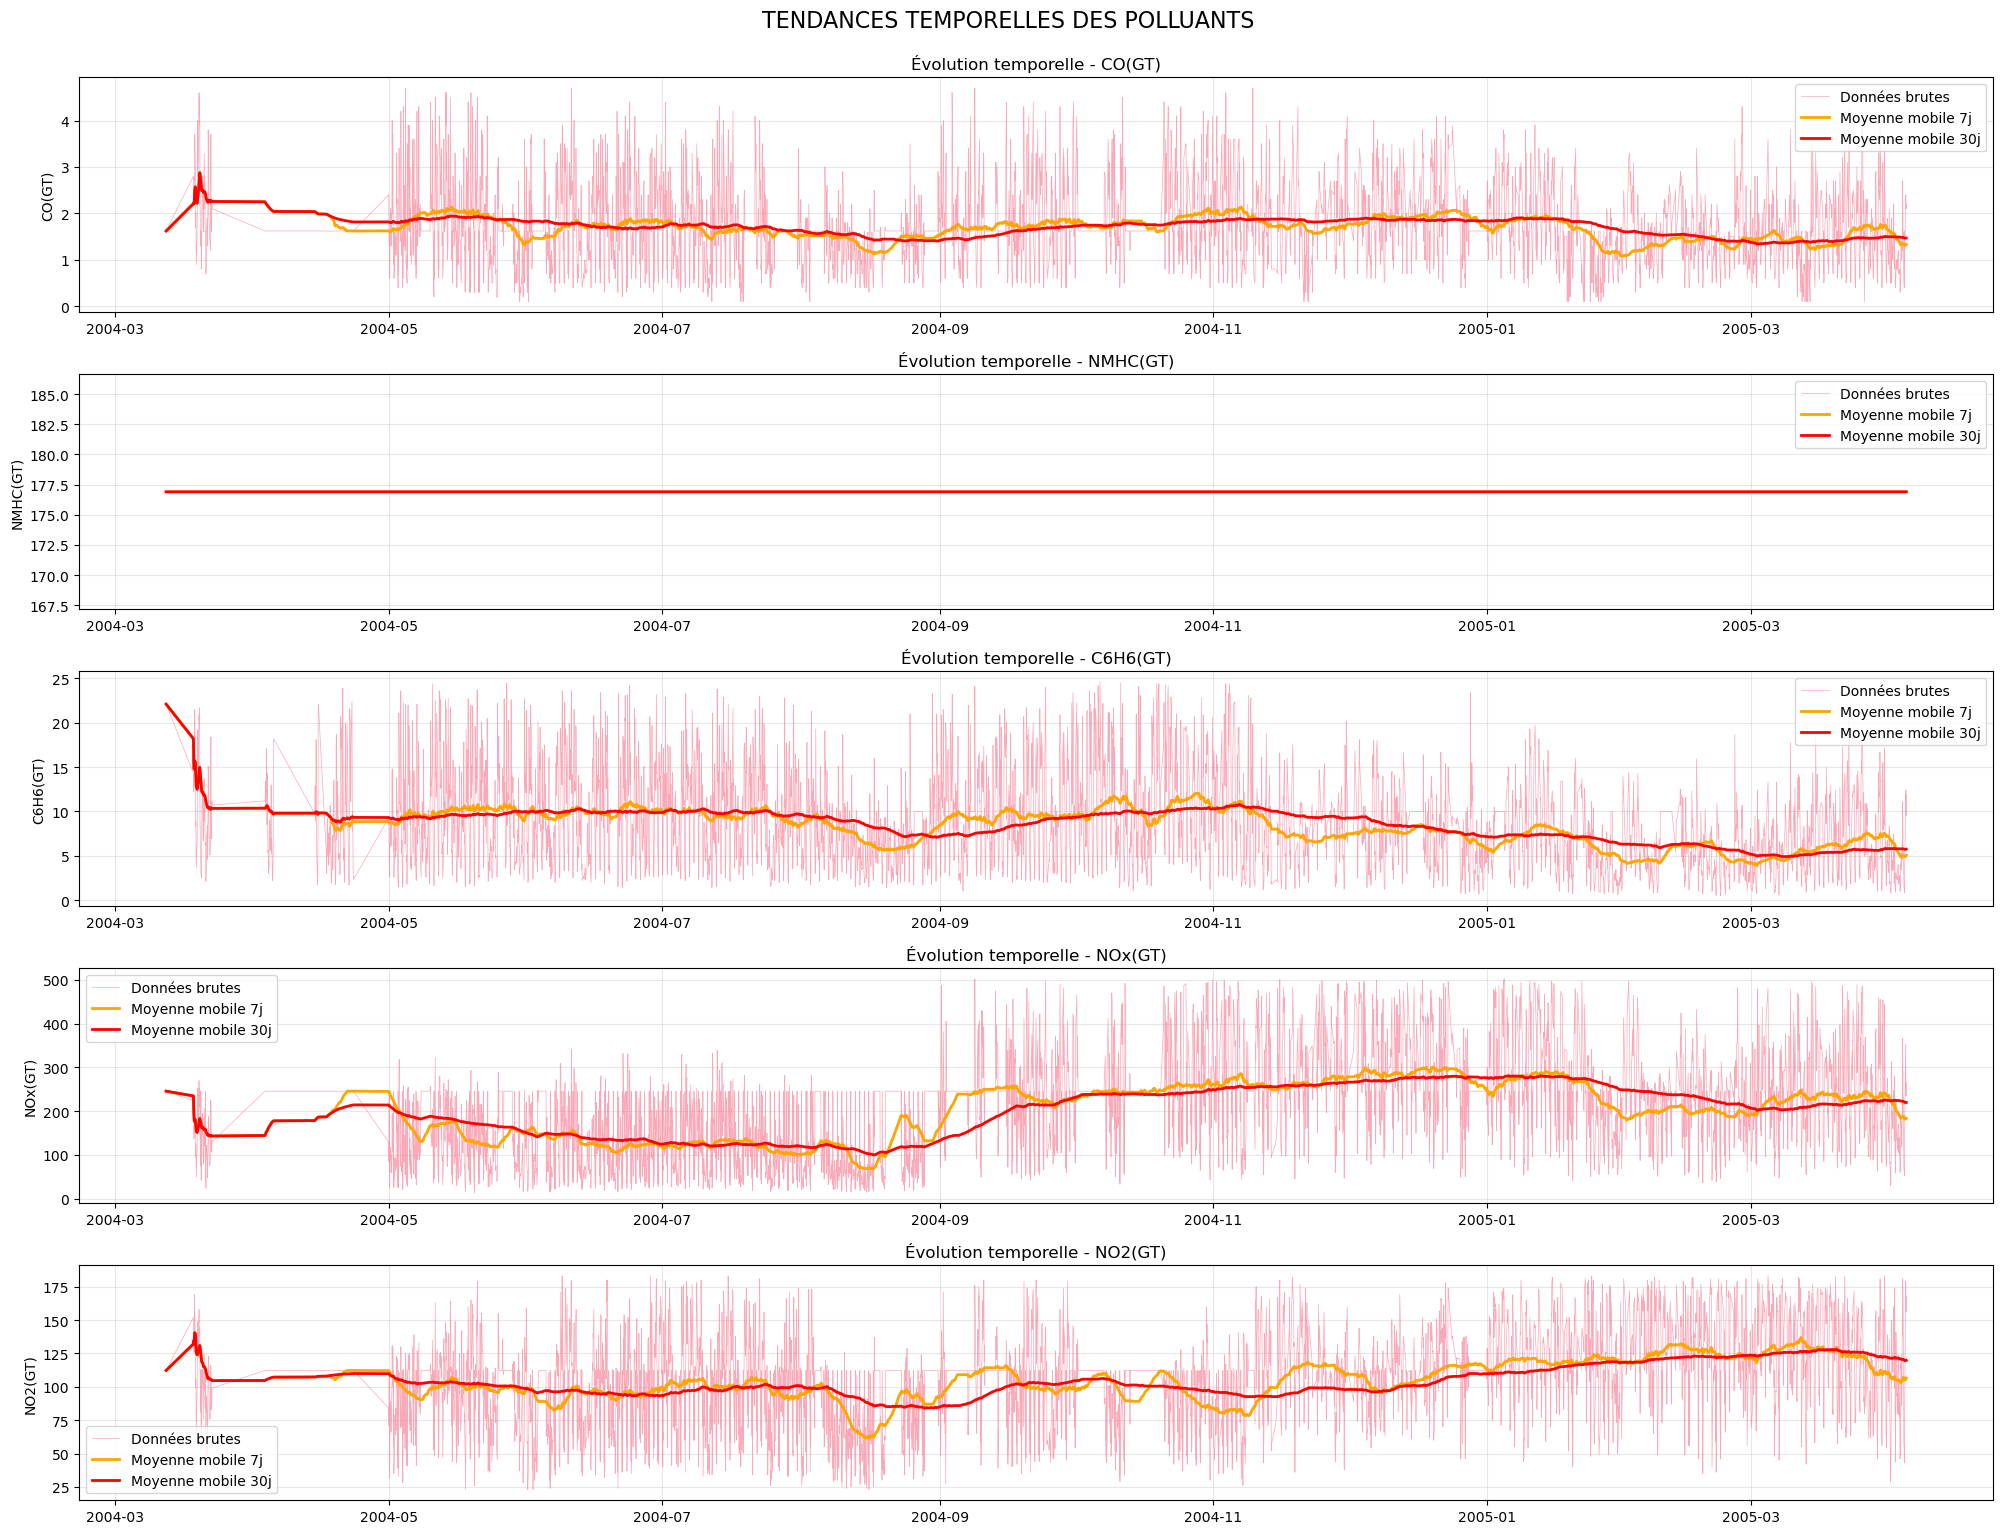


🌱 2. ANALYSE SAISONNIÈRE
--------------------------------------------------


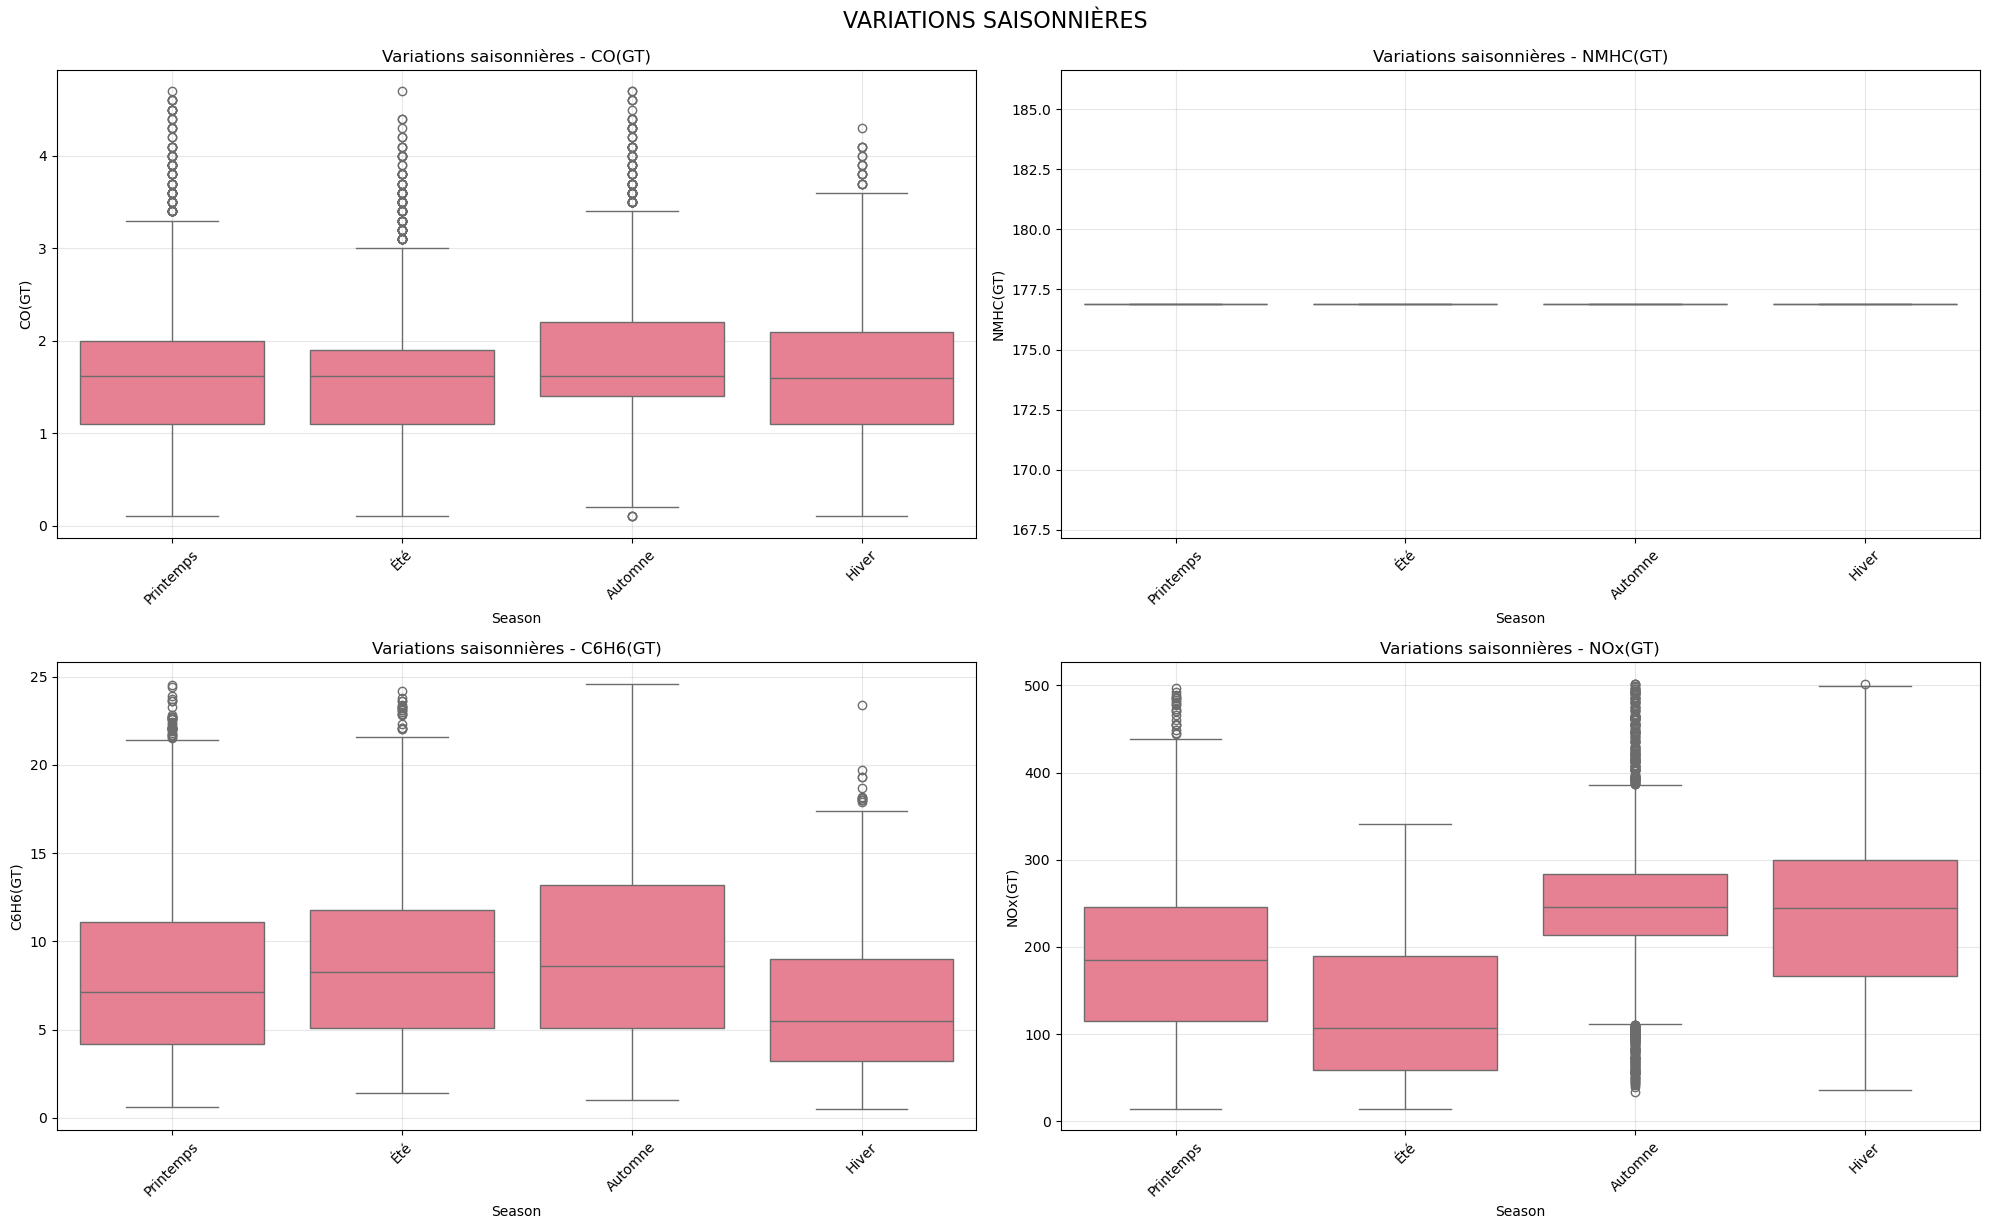

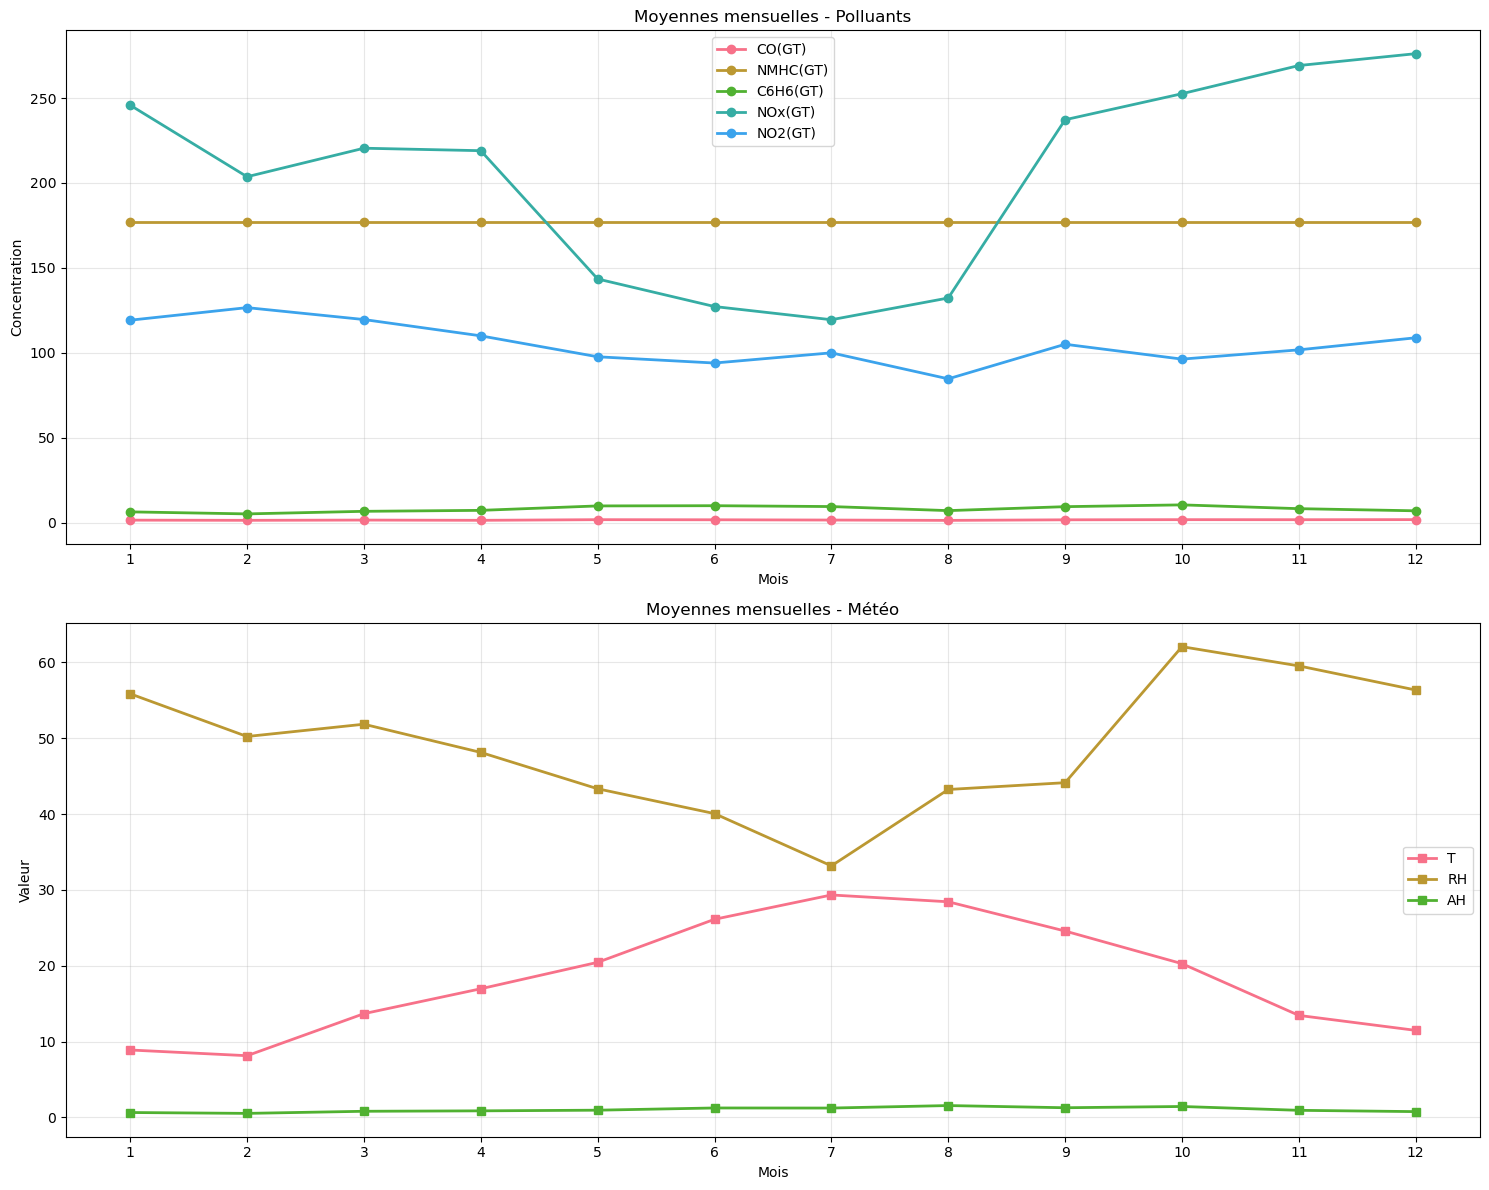


📊 STATISTIQUES SAISONNIÈRES:
          CO(GT)                 NMHC(GT)                    C6H6(GT)        \
            mean   std  min  max     mean  std    min    max     mean   std   
Season                                                                        
Automne     1.80  0.83  0.1  4.7    176.9  0.0  176.9  176.9     9.56  5.55   
Hiver       1.63  0.78  0.1  4.3    176.9  0.0  176.9  176.9     6.28  3.84   
Printemps   1.67  0.83  0.1  4.7    176.9  0.0  176.9  176.9     8.18  5.11   
Été         1.59  0.75  0.1  4.7    176.9  0.0  176.9  176.9     8.87  4.75   

                     NOx(GT)                      NO2(GT)                      
           min   max    mean     std   min    max    mean    std   min    max  
Season                                                                         
Automne    1.0  24.6  251.42   95.47  33.0  502.0  101.00  28.31  26.0  182.0  
Hiver      0.5  23.4  243.50  105.98  36.0  502.0  117.95  29.97  35.0  183.0  
Printemps  0.6  

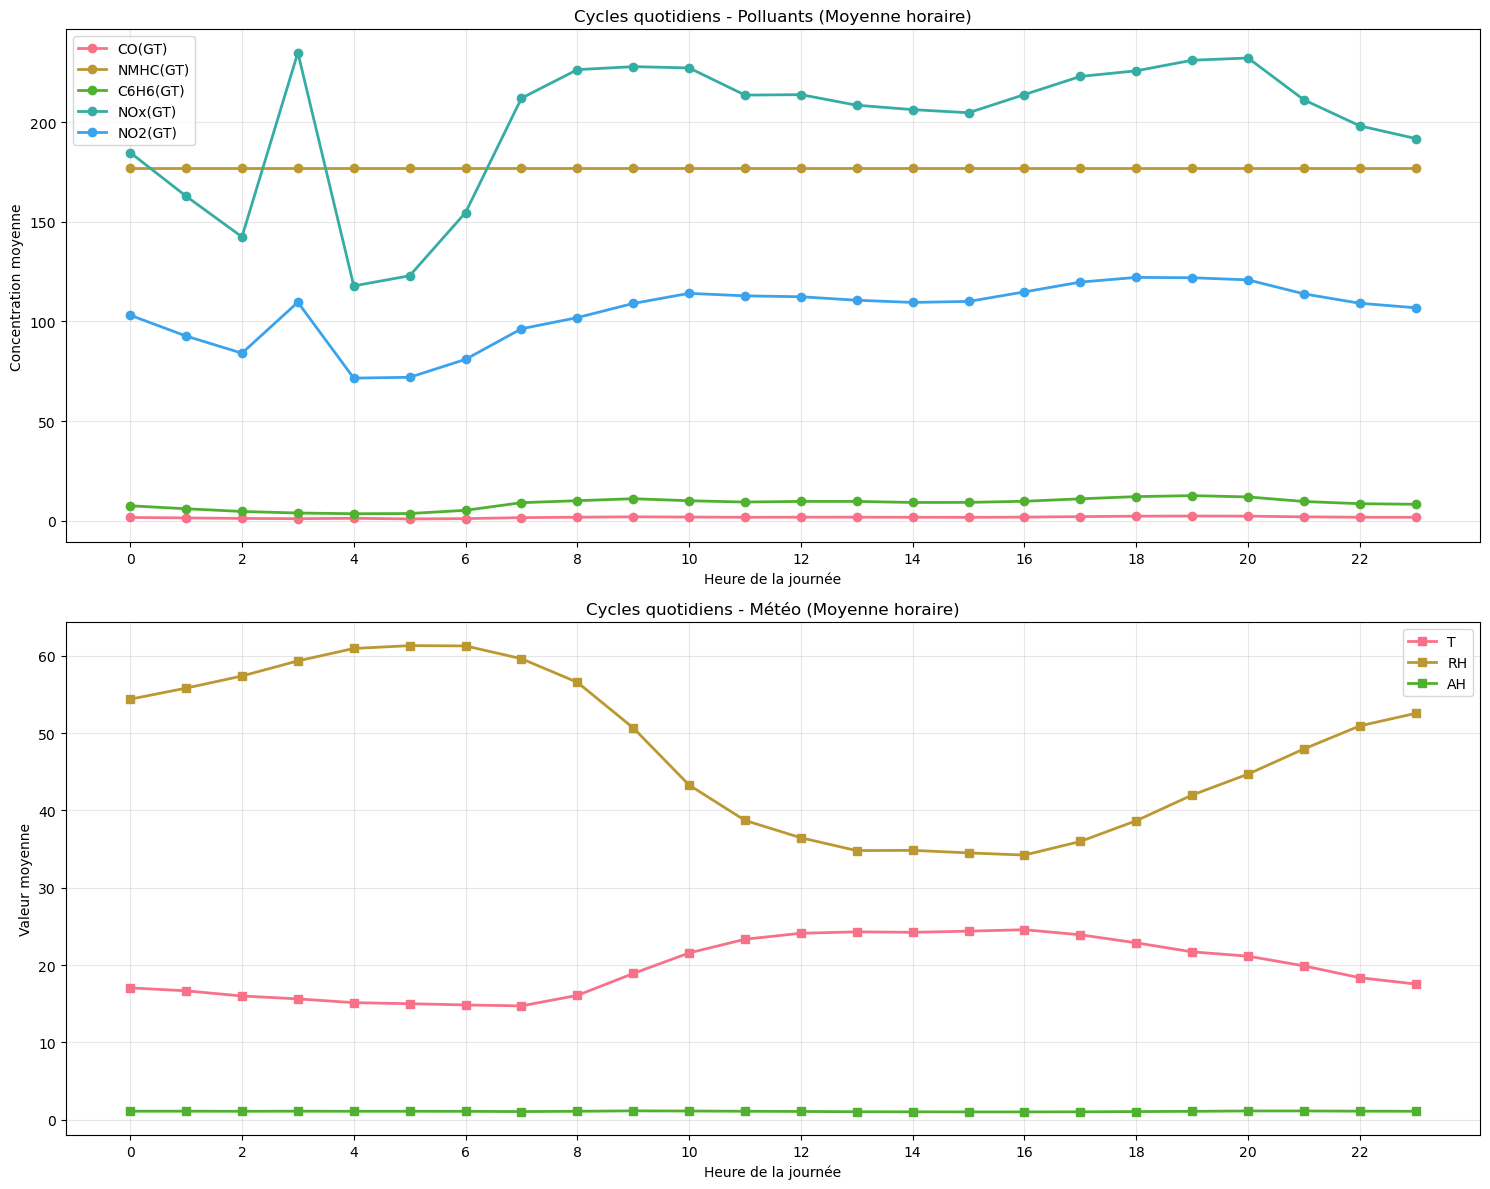

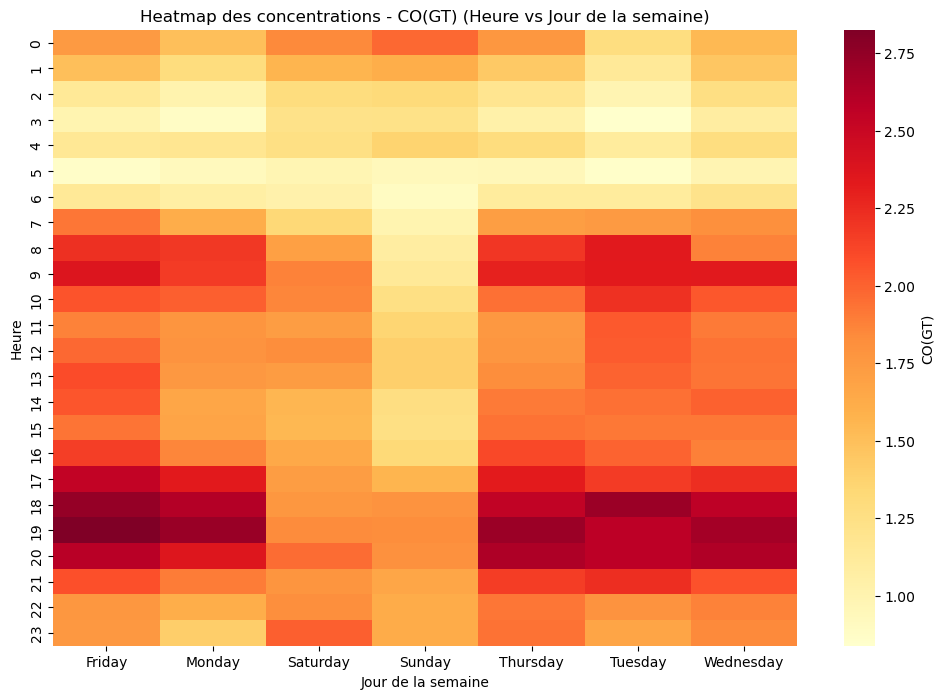

✅ Analyse des cycles quotidiens complétée
• Pics de pollution: 19h
• Minimum de pollution: 5h

📅 4. PATTERNS HEBDOMADAIRES
--------------------------------------------------


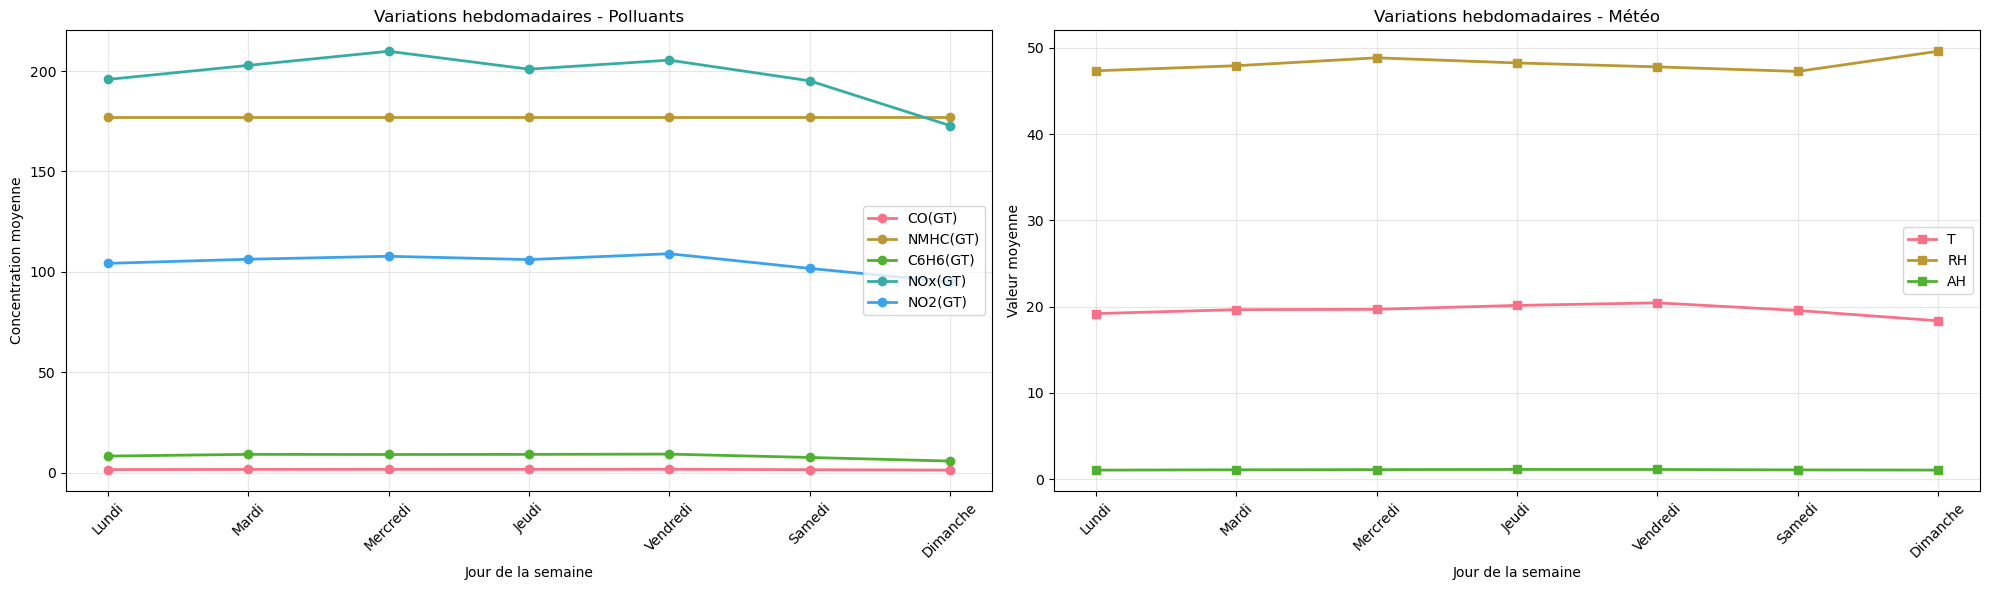


🔄 5. AUTOCORRÉLATIONS
--------------------------------------------------


c:\Users\0000\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1491: ValueWarning: Matrix is singular. Using pinv.
  warnings.warn("Matrix is singular. Using pinv.", ValueWarning)


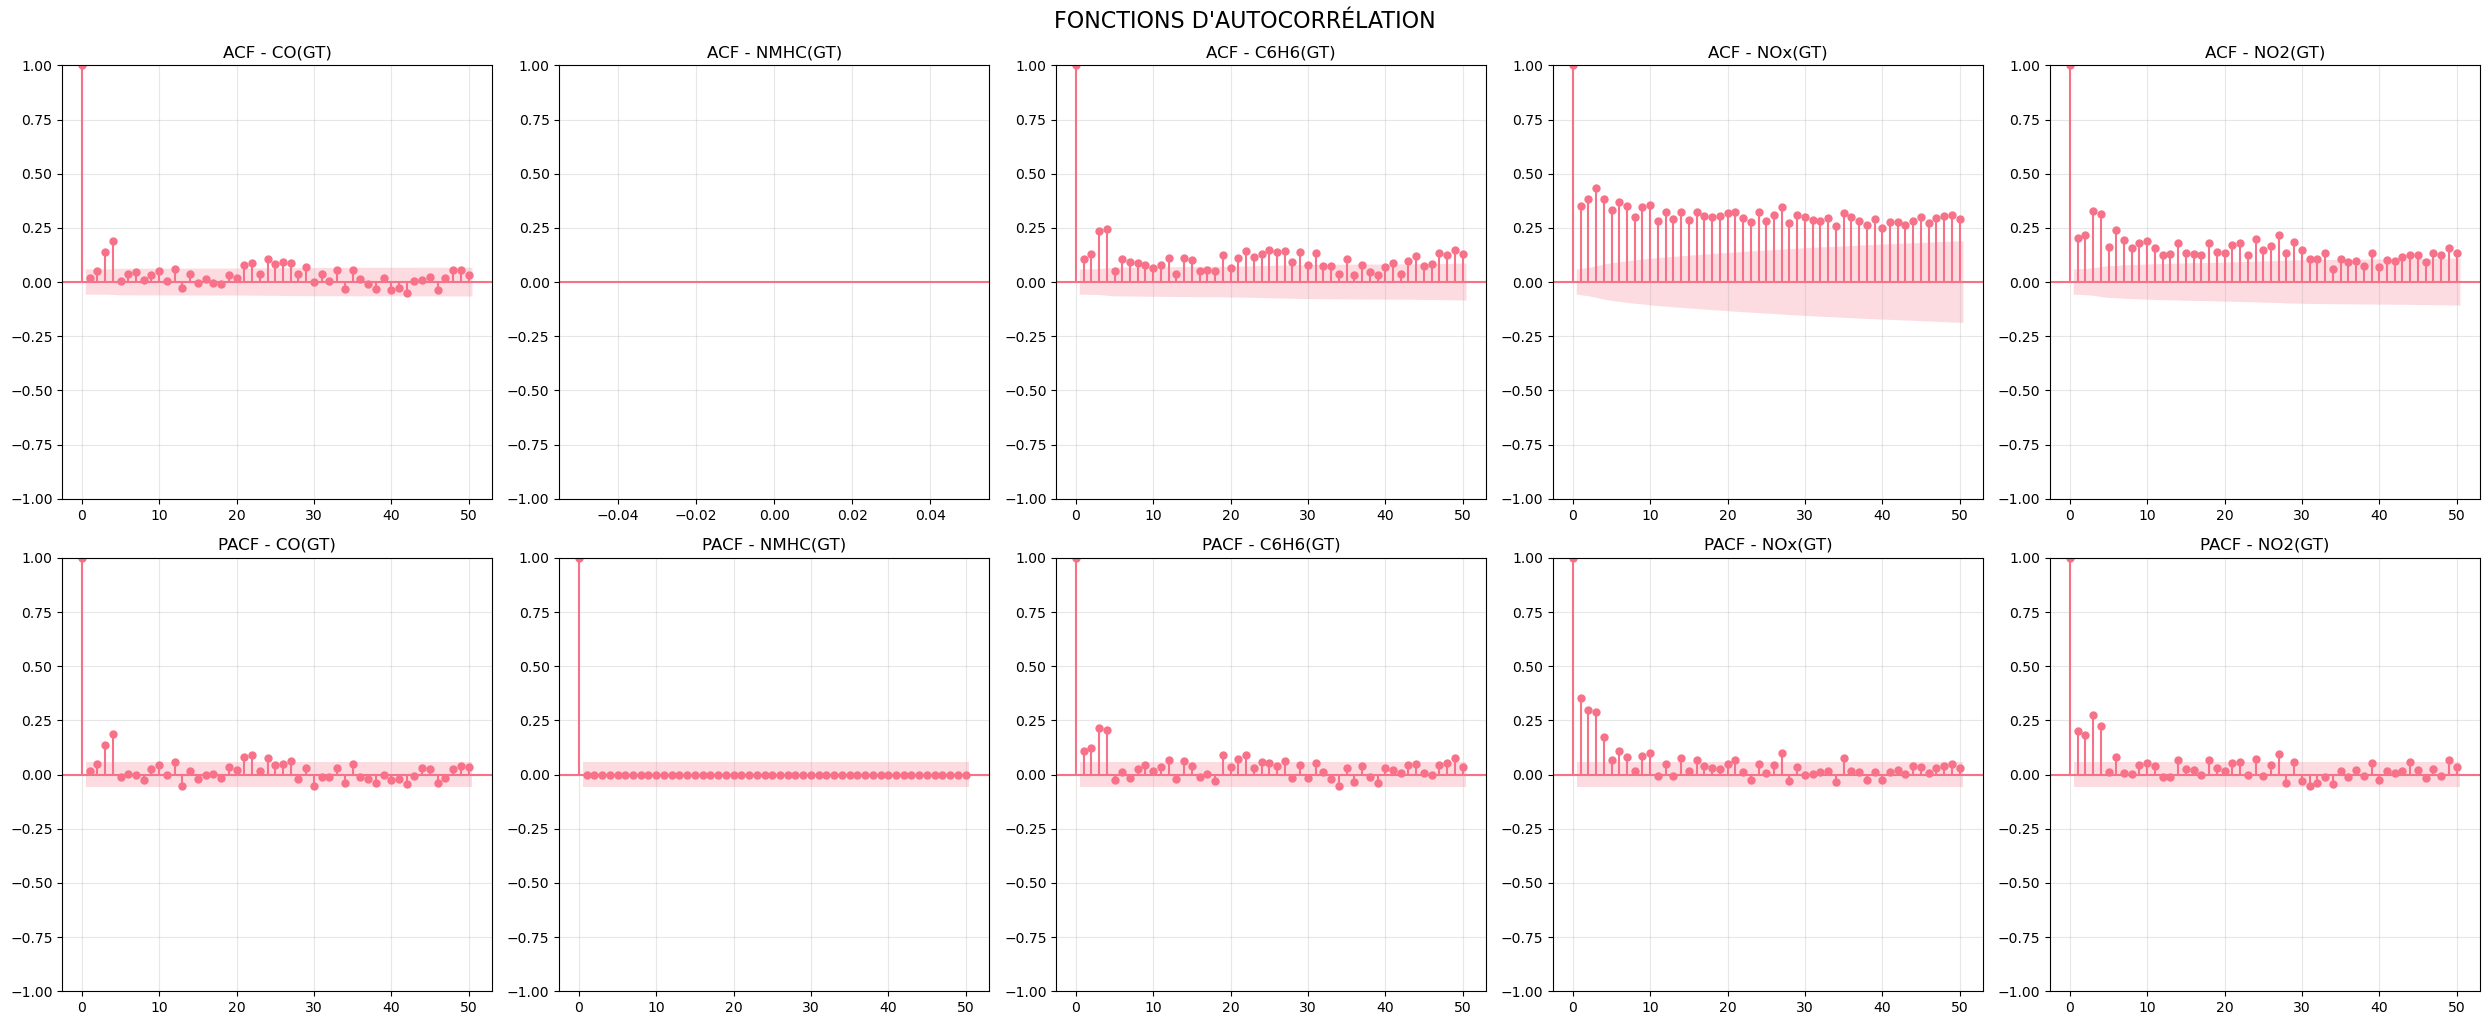


📋 RÉSUMÉ DES AUTOCORRÉLATIONS:
• CO(GT):
  - Autocorrélation max (1-24 lags): 0.188
  - Lags significatifs: [3, 4, 24]
• NMHC(GT):
  - Autocorrélation max (1-24 lags): nan
  - Lags significatifs: []
• C6H6(GT):
  - Autocorrélation max (1-24 lags): 0.244
  - Lags significatifs: [1, 2, 3, 4, 6]
• NOx(GT):
  - Autocorrélation max (1-24 lags): 0.432
  - Lags significatifs: [1, 2, 3, 4, 5]
• NO2(GT):
  - Autocorrélation max (1-24 lags): 0.327
  - Lags significatifs: [1, 2, 3, 4, 5]

🔀 6. CORRÉLATIONS CROISÉES TEMPORELLES
--------------------------------------------------

📊 CORRÉLATIONS POLLUANTS vs MÉTÉO:
Format: corrélation(0h), corrélation(décalage 1h)
                                 T                        RH  \
CO(GT)      0.148 (0h), 0.140 (1h)  -0.090 (0h), -0.082 (1h)   
NMHC(GT)     nan (0h), -0.000 (1h)     nan (0h), -0.000 (1h)   
C6H6(GT)    0.375 (0h), 0.358 (1h)  -0.217 (0h), -0.197 (1h)   
NOx(GT)   -0.249 (0h), -0.268 (1h)    0.165 (0h), 0.185 (1h)   
NO2(GT)   -0.122 (0h

In [4]:

# Configuration des graphiques
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (15, 8)

def analyze_temporal_patterns(data):
    
    print("="*70)
    print("ANALYSE TEMPORELLE - DATASET QUALITÉ DE L'AIR")
    print("="*70)
    
    # Préparation des données temporelles
    df = data.copy()
    df['DateTime'] = pd.to_datetime(df['DateTime'])
    df = df.set_index('DateTime').sort_index()
    
    # Extraction des composantes temporelles
    df['Year'] = df.index.year
    df['Month'] = df.index.month
    df['Day'] = df.index.day
    df['Hour'] = df.index.hour
    df['DayOfWeek'] = df.index.dayofweek
    df['DayName'] = df.index.day_name()
    df['MonthName'] = df.index.month_name()
    df['Season'] = df.index.month.map({12: 'Hiver', 1: 'Hiver', 2: 'Hiver',
                                       3: 'Printemps', 4: 'Printemps', 5: 'Printemps',
                                       6: 'Été', 7: 'Été', 8: 'Été',
                                       9: 'Automne', 10: 'Automne', 11: 'Automne'})
    
    # Colonnes des polluants et météo
    pollutant_cols = [col for col in df.columns if 'GT' in col or 'PT08' in col]
    weather_cols = ['T', 'RH', 'AH']
    main_pollutants = [col for col in df.columns if 'GT' in col]  # Focus sur les mesures de référence
    
    print(f"\n📅 PÉRIODE D'ANALYSE:")
    print(f"• Du {df.index.min()} au {df.index.max()}")
    print(f"• Durée totale: {(df.index.max() - df.index.min()).days} jours")
    print(f"• Fréquence d'échantillonnage: {pd.infer_freq(df.index) or 'Variable'}")
    
    # 1. TENDANCES TEMPORELLES GÉNÉRALES
    print(f"\n📈 1. TENDANCES TEMPORELLES")
    print("-" * 50)
    
    # Évolution des polluants principaux dans le temps
    fig, axes = plt.subplots(len(main_pollutants), 1, figsize=(20, 3*len(main_pollutants)))
    if len(main_pollutants) == 1:
        axes = [axes]
    
    for i, col in enumerate(main_pollutants):
        # Série temporelle complète
        axes[i].plot(df.index, df[col], alpha=0.6, linewidth=0.5, label='Données brutes')
        
        # Moyenne mobile pour la tendance
        df[f'{col}_MA7'] = df[col].rolling(window=7*24, min_periods=1).mean()  # 7 jours
        df[f'{col}_MA30'] = df[col].rolling(window=30*24, min_periods=1).mean()  # 30 jours
        
        axes[i].plot(df.index, df[f'{col}_MA7'], color='orange', linewidth=2, label='Moyenne mobile 7j')
        axes[i].plot(df.index, df[f'{col}_MA30'], color='red', linewidth=2, label='Moyenne mobile 30j')
        
        axes[i].set_title(f'Évolution temporelle - {col}')
        axes[i].set_ylabel(col)
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.suptitle('TENDANCES TEMPORELLES DES POLLUANTS', fontsize=16, y=1.02)
    plt.show()
    
    # 2. ANALYSE SAISONNIÈRE
    print(f"\n🌱 2. ANALYSE SAISONNIÈRE")
    print("-" * 50)
    
    # A. Box plots par saison
    fig, axes = plt.subplots(2, 2, figsize=(20, 12))
    axes = axes.ravel()
    
    for i, col in enumerate(main_pollutants[:4]):  # Limiter à 4 polluants principaux
        if i < len(axes):
            sns.boxplot(data=df, x='Season', y=col, ax=axes[i], 
                       order=['Printemps', 'Été', 'Automne', 'Hiver'])
            axes[i].set_title(f'Variations saisonnières - {col}')
            axes[i].tick_params(axis='x', rotation=45)
            axes[i].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.suptitle('VARIATIONS SAISONNIÈRES', fontsize=16, y=1.02)
    plt.show()
    
    # B. Moyennes mensuelles
    monthly_means = df.groupby('Month')[main_pollutants + weather_cols].mean()
    
    fig, axes = plt.subplots(2, 1, figsize=(15, 12))
    
    # Polluants
    for col in main_pollutants:
        axes[0].plot(monthly_means.index, monthly_means[col], marker='o', linewidth=2, label=col)
    axes[0].set_title('Moyennes mensuelles - Polluants')
    axes[0].set_xlabel('Mois')
    axes[0].set_ylabel('Concentration')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xticks(range(1, 13))
    
    # Variables météo
    for col in weather_cols:
        axes[1].plot(monthly_means.index, monthly_means[col], marker='s', linewidth=2, label=col)
    axes[1].set_title('Moyennes mensuelles - Météo')
    axes[1].set_xlabel('Mois')
    axes[1].set_ylabel('Valeur')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xticks(range(1, 13))
    
    plt.tight_layout()
    plt.show()
    
    # Statistiques saisonnières
    seasonal_stats = df.groupby('Season')[main_pollutants].agg(['mean', 'std', 'min', 'max'])
    print("\n📊 STATISTIQUES SAISONNIÈRES:")
    print(seasonal_stats.round(2))
    
    # 3. CYCLES QUOTIDIENS (si granularité horaire disponible)
    print(f"\n⏰ 3. CYCLES QUOTIDIENS")
    print("-" * 50)
    
    # Vérifier si on a des données horaires
    if df.index.to_series().dt.hour.nunique() > 1:
        # Moyennes horaires
        hourly_means = df.groupby('Hour')[main_pollutants + weather_cols].mean()
        
        fig, axes = plt.subplots(2, 1, figsize=(15, 12))
        
        # Polluants par heure
        for col in main_pollutants:
            axes[0].plot(hourly_means.index, hourly_means[col], marker='o', linewidth=2, label=col)
        axes[0].set_title('Cycles quotidiens - Polluants (Moyenne horaire)')
        axes[0].set_xlabel('Heure de la journée')
        axes[0].set_ylabel('Concentration moyenne')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)
        axes[0].set_xticks(range(0, 24, 2))
        
        # Météo par heure
        for col in weather_cols:
            axes[1].plot(hourly_means.index, hourly_means[col], marker='s', linewidth=2, label=col)
        axes[1].set_title('Cycles quotidiens - Météo (Moyenne horaire)')
        axes[1].set_xlabel('Heure de la journée')
        axes[1].set_ylabel('Valeur moyenne')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_xticks(range(0, 24, 2))
        
        plt.tight_layout()
        plt.show()
        
        # Heatmap des patterns horaires par jour de la semaine
        pivot_data = df.pivot_table(values=main_pollutants[0], 
                                   index='Hour', 
                                   columns='DayName', 
                                   aggfunc='mean')
        
        plt.figure(figsize=(12, 8))
        sns.heatmap(pivot_data, annot=False, cmap='YlOrRd', cbar_kws={'label': f'{main_pollutants[0]}'})
        plt.title(f'Heatmap des concentrations - {main_pollutants[0]} (Heure vs Jour de la semaine)')
        plt.ylabel('Heure')
        plt.xlabel('Jour de la semaine')
        plt.show()
        
        print(f"✅ Analyse des cycles quotidiens complétée")
        print(f"• Pics de pollution: {hourly_means[main_pollutants[0]].idxmax()}h")
        print(f"• Minimum de pollution: {hourly_means[main_pollutants[0]].idxmin()}h")
        
    else:
        print("⚠️ Pas de granularité horaire détectée - Cycles quotidiens non analysables")
    
    # 4. ANALYSE DES JOURS DE LA SEMAINE
    print(f"\n📅 4. PATTERNS HEBDOMADAIRES")
    print("-" * 50)
    
    weekly_means = df.groupby('DayOfWeek')[main_pollutants + weather_cols].mean()
    day_names = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))
    
    # Polluants par jour de la semaine
    for col in main_pollutants:
        axes[0].plot(range(7), weekly_means[col], marker='o', linewidth=2, label=col)
    axes[0].set_title('Variations hebdomadaires - Polluants')
    axes[0].set_xlabel('Jour de la semaine')
    axes[0].set_ylabel('Concentration moyenne')
    axes[0].set_xticks(range(7))
    axes[0].set_xticklabels(day_names, rotation=45)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Météo par jour de la semaine
    for col in weather_cols:
        axes[1].plot(range(7), weekly_means[col], marker='s', linewidth=2, label=col)
    axes[1].set_title('Variations hebdomadaires - Météo')
    axes[1].set_xlabel('Jour de la semaine')
    axes[1].set_ylabel('Valeur moyenne')
    axes[1].set_xticks(range(7))
    axes[1].set_xticklabels(day_names, rotation=45)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 5. AUTOCORRÉLATIONS
    print(f"\n🔄 5. AUTOCORRÉLATIONS")
    print("-" * 50)
    
    # Calculer et afficher les autocorrélations pour les principaux polluants
    fig, axes = plt.subplots(2, len(main_pollutants), figsize=(5*len(main_pollutants), 10))
    if len(main_pollutants) == 1:
        axes = axes.reshape(-1, 1)
    
    autocorr_summary = {}
    
    for i, col in enumerate(main_pollutants):
        # Prendre un échantillon pour accélérer le calcul
        sample_data = df[col].dropna()
        if len(sample_data) > 1000:
            sample_data = sample_data.iloc[::max(1, len(sample_data)//1000)]
        
        # Autocorrélation (ACF)
        plot_acf(sample_data, ax=axes[0, i], lags=50, title=f'ACF - {col}')
        axes[0, i].grid(True, alpha=0.3)
        
        # Autocorrélation partielle (PACF)
        plot_pacf(sample_data, ax=axes[1, i], lags=50, title=f'PACF - {col}')
        axes[1, i].grid(True, alpha=0.3)
        
        # Calcul des valeurs d'autocorrélation significatives
        acf_values = acf(sample_data, nlags=50, fft=True)
        significant_lags = np.where(np.abs(acf_values[1:]) > 0.1)[0] + 1  # Seuil arbitraire de 0.1
        
        autocorr_summary[col] = {
            'max_autocorr': np.max(np.abs(acf_values[1:25])),  # Sur 24 premiers lags
            'significant_lags': list(significant_lags[:5]) if len(significant_lags) > 0 else []
        }
    
    plt.tight_layout()
    plt.suptitle('FONCTIONS D\'AUTOCORRÉLATION', fontsize=16, y=1.02)
    plt.show()
    
    # Résumé des autocorrélations
    print("\n📋 RÉSUMÉ DES AUTOCORRÉLATIONS:")
    for col, stats in autocorr_summary.items():
        print(f"• {col}:")
        print(f"  - Autocorrélation max (1-24 lags): {stats['max_autocorr']:.3f}")
        print(f"  - Lags significatifs: {stats['significant_lags']}")
    
    # 6. CORRÉLATIONS CROISÉES TEMPORELLES
    print(f"\n🔀 6. CORRÉLATIONS CROISÉES TEMPORELLES")
    print("-" * 50)
    
    # Matrice de corrélation avec décalages temporels
    cross_corr_matrix = pd.DataFrame(index=main_pollutants, columns=weather_cols)
    
    for pollutant in main_pollutants:
        for weather_var in weather_cols:
            # Corrélation sans décalage
            corr_0 = df[pollutant].corr(df[weather_var])
            
            # Corrélation avec décalage de 1 heure (si données horaires)
            try:
                corr_1h = df[pollutant].corr(df[weather_var].shift(1))
                corr_summary = f"{corr_0:.3f} (0h), {corr_1h:.3f} (1h)"
            except:
                corr_summary = f"{corr_0:.3f}"
            
            cross_corr_matrix.loc[pollutant, weather_var] = corr_summary
    
    print("\n📊 CORRÉLATIONS POLLUANTS vs MÉTÉO:")
    print("Format: corrélation(0h), corrélation(décalage 1h)")
    print(cross_corr_matrix)
    
    return df, {
        'seasonal_stats': seasonal_stats,
        'monthly_means': monthly_means,
        'hourly_means': hourly_means if 'hourly_means' in locals() else None,
        'weekly_means': weekly_means,
        'autocorr_summary': autocorr_summary,
        'cross_corr_matrix': cross_corr_matrix
    }

# UTILISATION:
df_temporal, temporal_results = analyze_temporal_patterns(data)

print("\n" + "="*70)
print("ANALYSE TEMPORELLE TERMINÉE")
print("="*70)


### Interpretion: Meteo-Polluant

#### ⭐ C6H6(GT) - Benzène

* T: +0.375 → Forte corrélation positive avec température !
* RH: -0.217 → Corrélation négative notable avec humidité

#### Interprétation :

1. Évaporation imporante des carburants pendant les temps chauds.
2. Moins de dispersion du benzène pendant les temps sec (l'été)
3. Le benzèn est le plus métoe-sensible


### Exemple d'explication de l'autocorrelation

#### Exemple: NO2(GT):
  - Autocorrélation max (1-24 lags): 0.327
  - Lags significatifs: [1, 2, 3, 4, 5]

#### 🔍 Décomposons l'exemple :
1. Autocorrélation max: 0.327

* Le NO2 à un moment donné est modérément corrélé (33%) avec ses valeurs passées
C'est une corrélation significative mais pas très forte
Cela indique une persistance temporelle : si le NO2 est élevé maintenant, il a tendance à rester relativement élevé dans les heures suivantes

2. Lags significatifs: [1, 2, 3, 4, 5]

* Lag 1 : Le NO2 actuel est corrélé avec la valeur d'1 heure avant
* Lag 2 : Corrélé avec la valeur de 2 heures avant
* Et ainsi de suite jusqu'à 5 heures

#### 🏭 Interprétation pour la qualité de l'air :
3. Pourquoi cette persistance ?

* Inertie atmosphérique : Les polluants ne se dispersent pas instantanément
* Sources continues : Trafic routier, industries émettent de façon continue
* Conditions météo stables : Vent faible = accumulation des polluants

#### Implications pratiques :

* ✅ Prédictibilité : Tu peux prédire le NO2 des prochaines heures en regardant les 5 dernières heures
* ⚠️ Épisodes de pollution : Une fois commencé, un pic de pollution tend à persister plusieurs heures
* 🔄 Cycles réguliers : Suggère des patterns récurrents (trafic quotidien)

#### 📊 Comparaison typique :

* 0.1-0.3 : Faible persistance (dispersions rapides)
* 0.3-0.6 : Persistance modérée ← TON CAS
* 0.6-0.9 : Forte persistance (accumulation)

## Etape3: Analyse Bivariée

ANALYSE DES RELATIONS ENTRE VARIABLES

📊 VARIABLES ANALYSÉES:
• Polluants GT (référence): 5
• Capteurs PT08: 5
• Variables météo: 3
• Total: 13 variables

🔗 1. MATRICE DE CORRÉLATION GÉNÉRALE
--------------------------------------------------


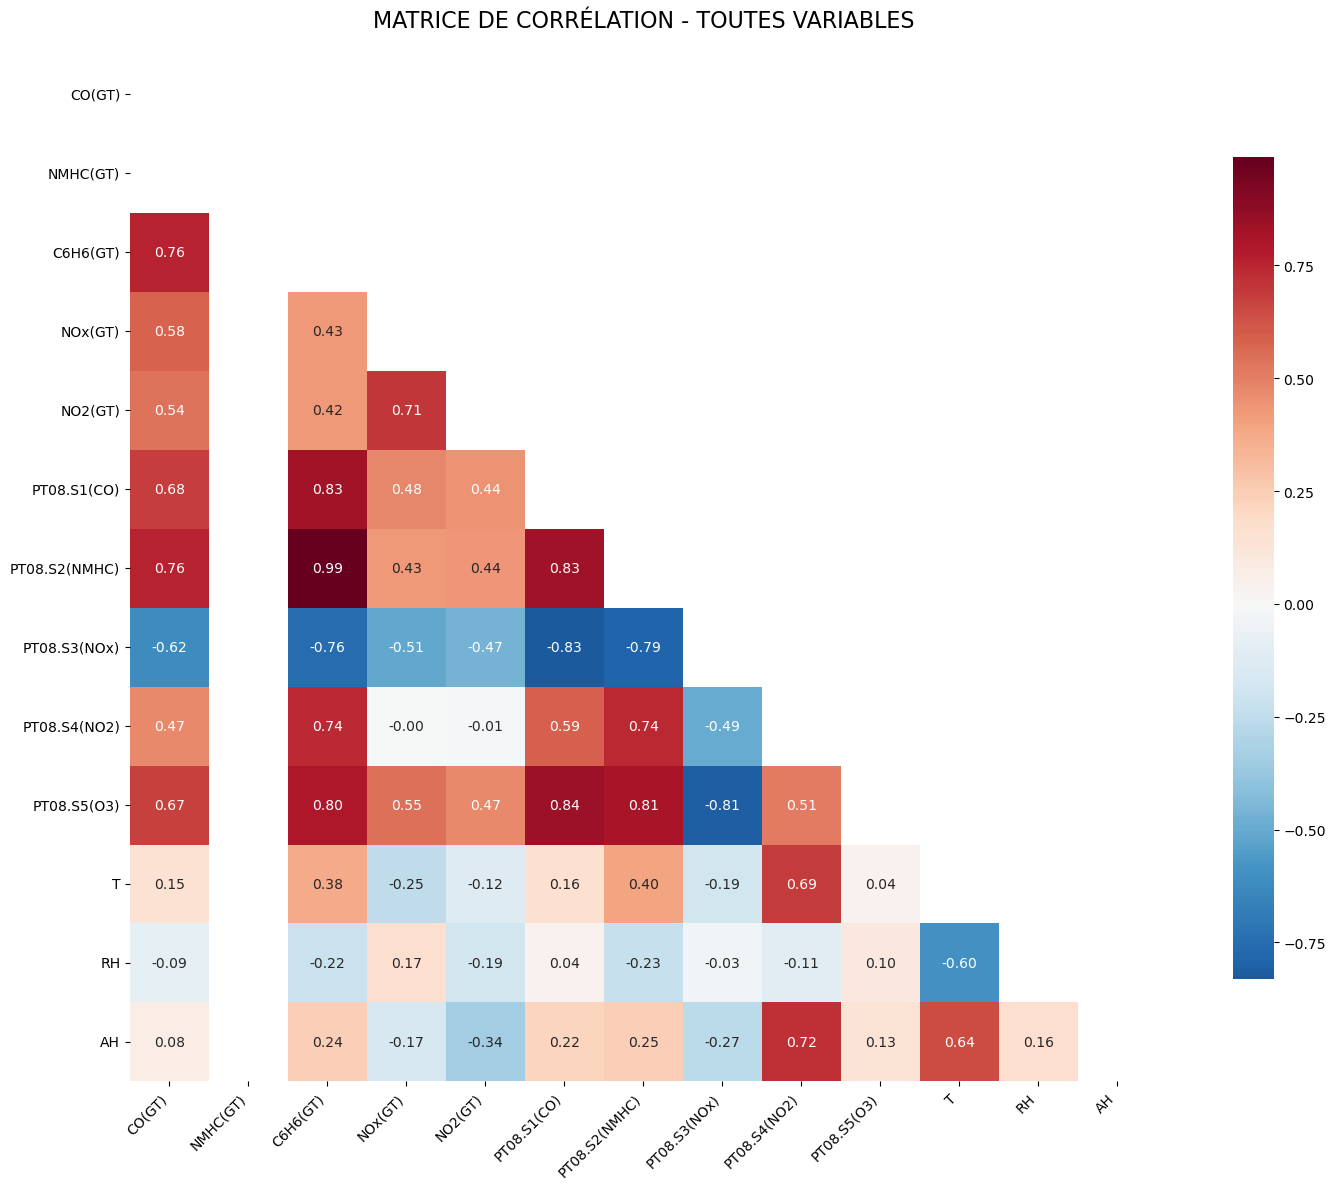


🔥 TOP 10 CORRÉLATIONS LES PLUS FORTES:
• PT08.S2(NMHC) ↔ C6H6(GT): 0.989
• PT08.S5(O3) ↔ PT08.S1(CO): 0.840
• PT08.S2(NMHC) ↔ PT08.S1(CO): 0.833
• PT08.S3(NOx) ↔ PT08.S1(CO): -0.830
• PT08.S1(CO) ↔ C6H6(GT): 0.829
• PT08.S5(O3) ↔ PT08.S2(NMHC): 0.812
• PT08.S5(O3) ↔ PT08.S3(NOx): -0.811
• PT08.S5(O3) ↔ C6H6(GT): 0.803
• PT08.S3(NOx) ↔ PT08.S2(NMHC): -0.792
• C6H6(GT) ↔ CO(GT): 0.759

❄️ TOP 5 CORRÉLATIONS LES PLUS FAIBLES:
• PT08.S4(NO2) ↔ NOx(GT): -0.000
• PT08.S4(NO2) ↔ NO2(GT): -0.011
• RH ↔ PT08.S3(NOx): -0.034
• T ↔ PT08.S5(O3): 0.037
• RH ↔ PT08.S1(CO): 0.042

📋 2. ANALYSE PAR BLOCS DE VARIABLES
--------------------------------------------------


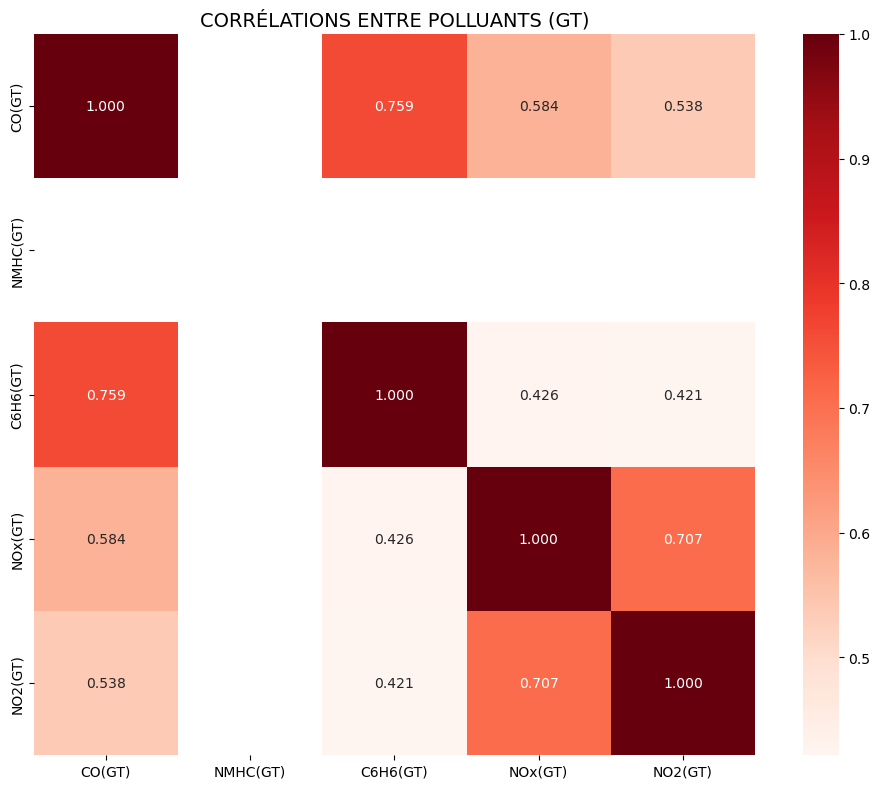

🏭 CORRÉLATIONS ENTRE POLLUANTS GT:
• CO(GT) ↔ NMHC(GT): nan
• CO(GT) ↔ C6H6(GT): 0.759
• CO(GT) ↔ NOx(GT): 0.584
• CO(GT) ↔ NO2(GT): 0.538
• NMHC(GT) ↔ C6H6(GT): nan
• NMHC(GT) ↔ NOx(GT): nan
• NMHC(GT) ↔ NO2(GT): nan
• C6H6(GT) ↔ NOx(GT): 0.426
• C6H6(GT) ↔ NO2(GT): 0.421
• NOx(GT) ↔ NO2(GT): 0.707


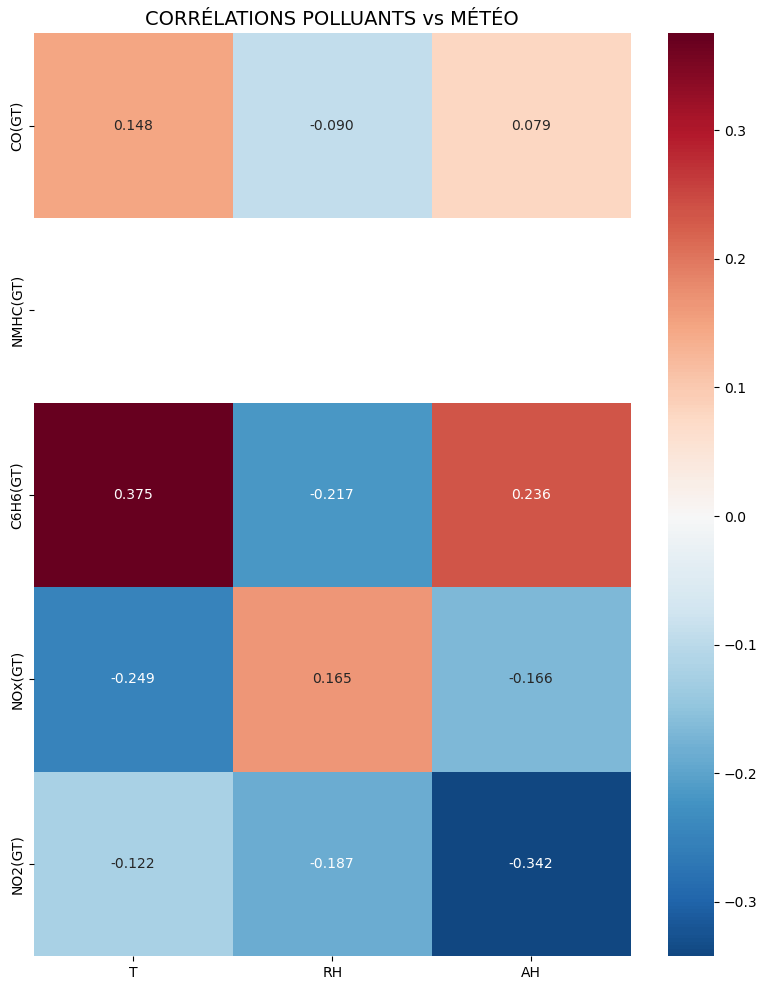


🌤️ ANALYSE POLLUANTS vs MÉTÉO:

• CO(GT):
  - vs T: 0.148 (Modérée positive)
  - vs RH: -0.090 (Faible négative)
  - vs AH: 0.079 (Faible positive)

• NMHC(GT):
  - vs T: nan (Faible négative)
  - vs RH: nan (Faible négative)
  - vs AH: nan (Faible négative)

• C6H6(GT):
  - vs T: 0.375 (Forte positive)
  - vs RH: -0.217 (Modérée négative)
  - vs AH: 0.236 (Modérée positive)

• NOx(GT):
  - vs T: -0.249 (Modérée négative)
  - vs RH: 0.165 (Modérée positive)
  - vs AH: -0.166 (Modérée négative)

• NO2(GT):
  - vs T: -0.122 (Modérée négative)
  - vs RH: -0.187 (Modérée négative)
  - vs AH: -0.342 (Forte négative)

📈 3. VISUALISATION DES RELATIONS CLÉS
--------------------------------------------------


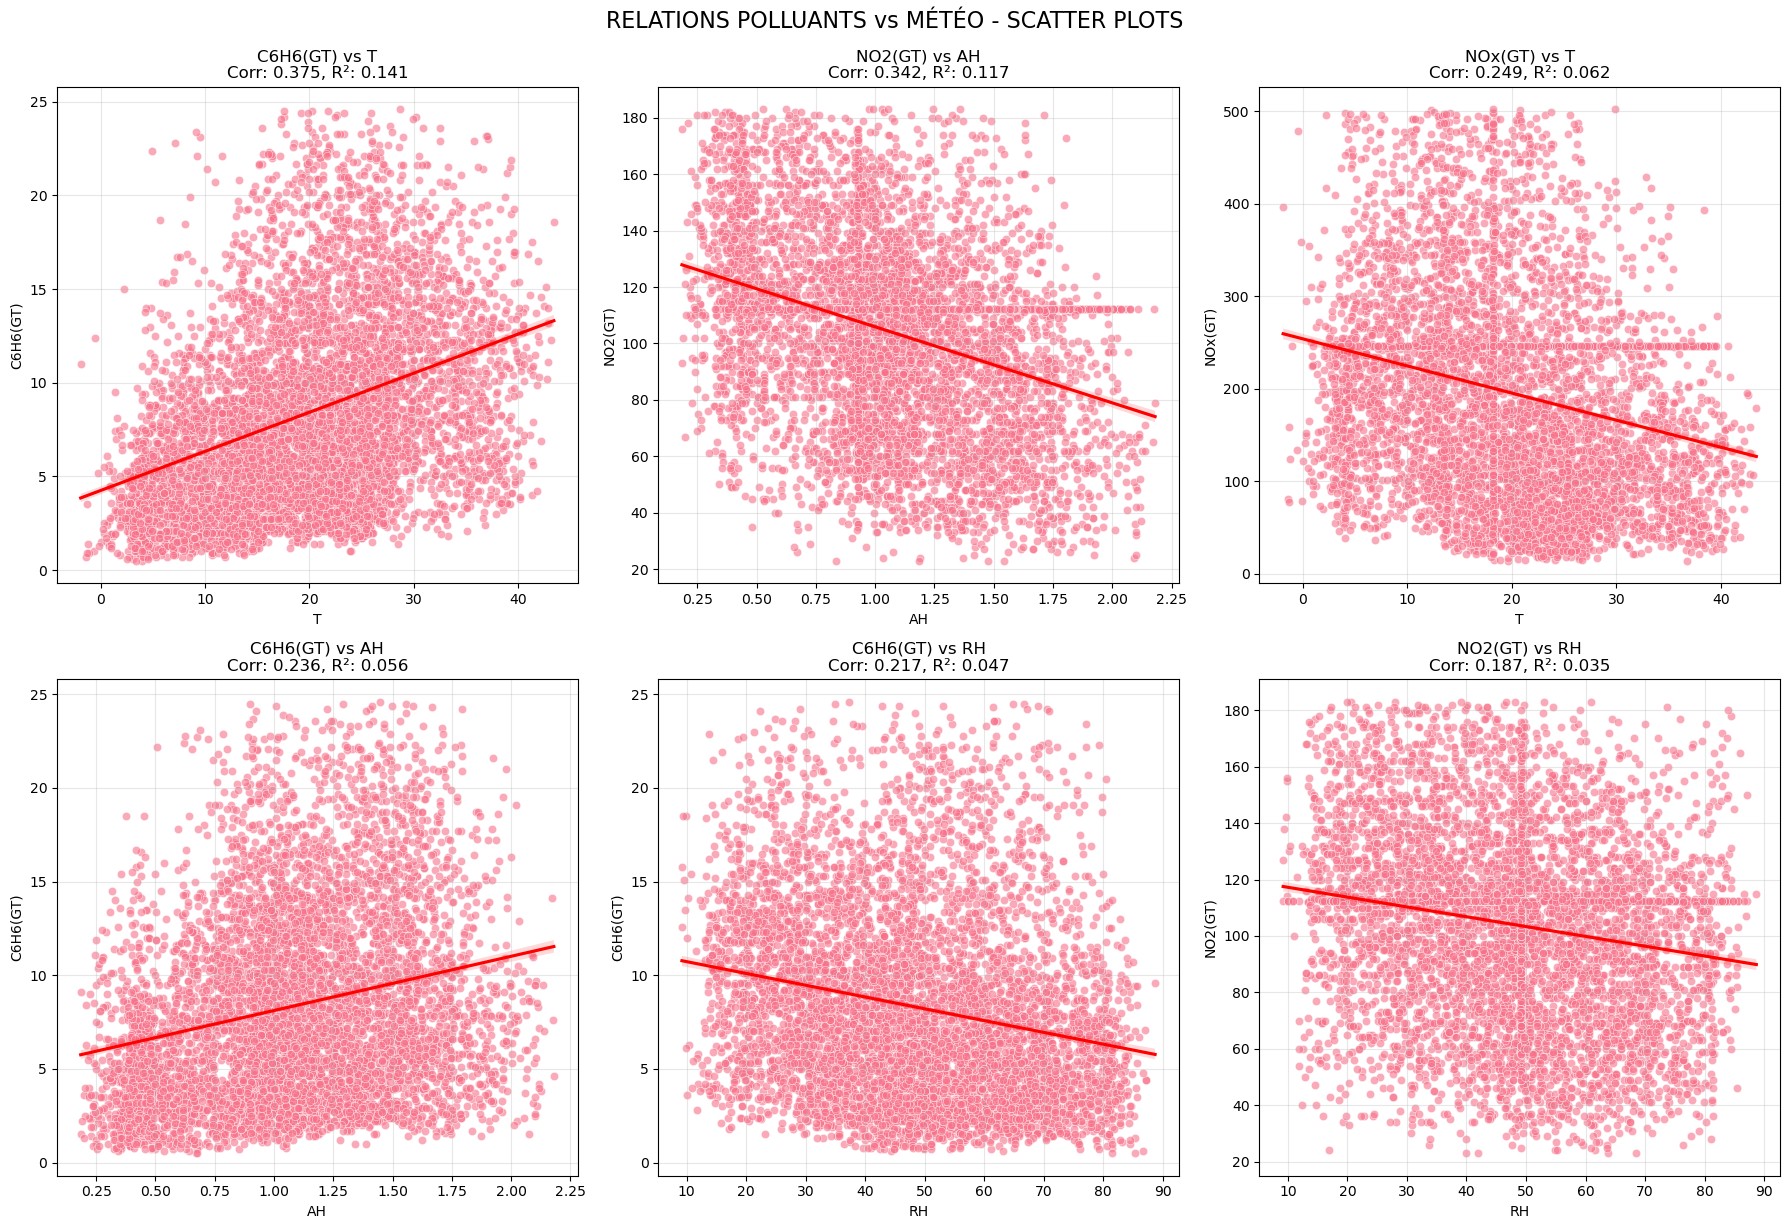


🔧 4. COMPARAISON CAPTEURS GT vs PT08
--------------------------------------------------
📊 STATISTIQUES DE COMPARAISON GT vs PT08:

• CO(GT) vs PT08.S1(CO):
  - Corrélation Pearson: 0.683 (p=0.00e+00)
  - Corrélation Spearman: 0.683
  - R²: 0.467
  - RMSE: 0.583
  - Nombre de points: 6,795
  - Qualité de correspondance: Bonne

• NMHC(GT) vs PT08.S2(NMHC):
  - Corrélation Pearson: nan (p=nan)
  - Corrélation Spearman: nan
  - R²: 0.000
  - RMSE: 0.000
  - Nombre de points: 6,795
  - Qualité de correspondance: Faible

• NOx(GT) vs PT08.S3(NOx):
  - Corrélation Pearson: -0.511 (p=0.00e+00)
  - Corrélation Spearman: -0.493
  - R²: 0.261
  - RMSE: 90.987
  - Nombre de points: 6,795
  - Qualité de correspondance: Faible

• NO2(GT) vs PT08.S4(NO2):
  - Corrélation Pearson: -0.011 (p=3.76e-01)
  - Corrélation Spearman: -0.016
  - R²: 0.000
  - RMSE: 32.153
  - Nombre de points: 6,795
  - Qualité de correspondance: Faible


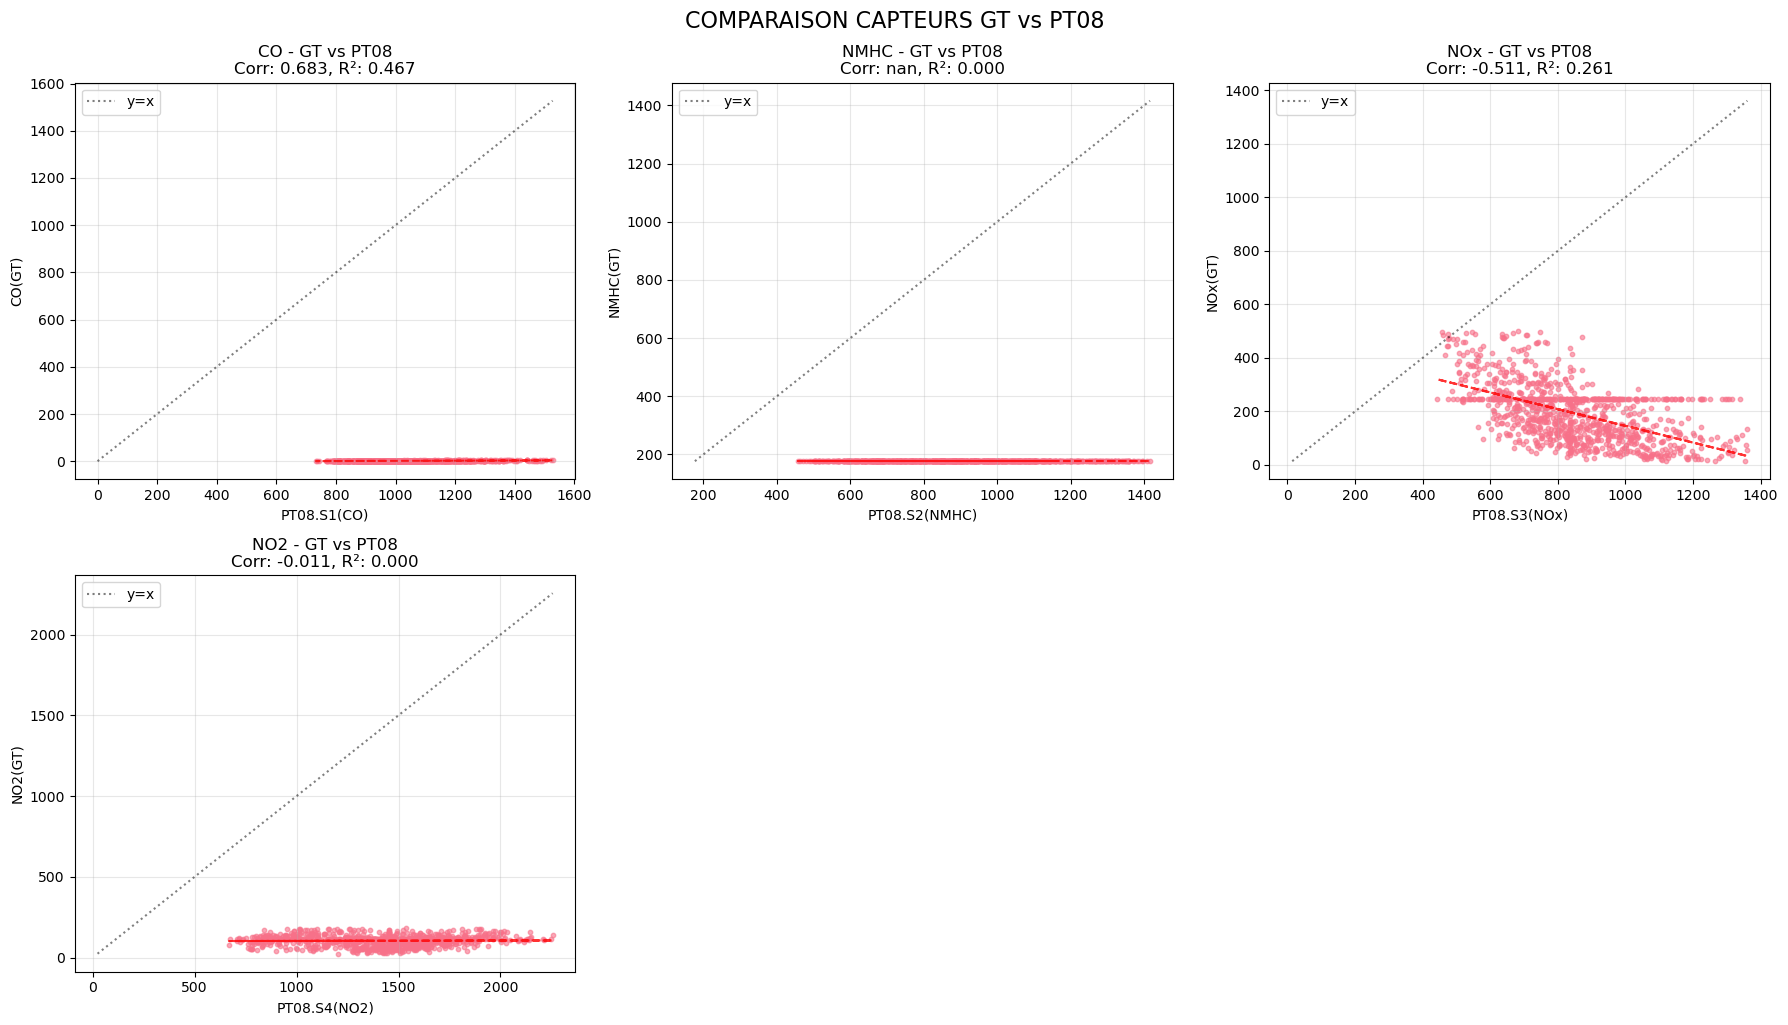


📋 5. RÉSUMÉ ET RECOMMANDATIONS
--------------------------------------------------
🏆 MEILLEUR CAPTEUR PT08: CO(GT)
   Corrélation: 0.683
🔧 CAPTEUR À AMÉLIORER: NOx(GT)
   Corrélation: -0.511

🌤️ VARIABLE MÉTÉO LA PLUS INFLUENTE: T
   Corrélation moyenne: 0.224

ANALYSE DES RELATIONS TERMINÉE


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)

def analyze_variable_relationships(data):
    """
    Analyse complète des relations entre variables pour le dataset de qualité de l'air
    """
    
    print("="*70)
    print("ANALYSE DES RELATIONS ENTRE VARIABLES")
    print("="*70)
    
    df = data.copy()
    
    # Colonnes par catégorie
    gt_cols = [col for col in df.columns if 'GT' in col]
    pt08_cols = [col for col in df.columns if 'PT08' in col]
    weather_cols = ['T', 'RH', 'AH']
    all_numeric = gt_cols + pt08_cols + weather_cols
    
    print(f"\n📊 VARIABLES ANALYSÉES:")
    print(f"• Polluants GT (référence): {len(gt_cols)}")
    print(f"• Capteurs PT08: {len(pt08_cols)}")
    print(f"• Variables météo: {len(weather_cols)}")
    print(f"• Total: {len(all_numeric)} variables")
    
    # 1. MATRICE DE CORRÉLATION COMPLÈTE
    print(f"\n🔗 1. MATRICE DE CORRÉLATION GÉNÉRALE")
    print("-" * 50)
    
    # Matrice de corrélation
    corr_matrix = df[all_numeric].corr()
    
    # Heatmap principale
    plt.figure(figsize=(16, 12))
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Masquer triangle supérieur
    
    sns.heatmap(corr_matrix, 
                mask=mask,
                annot=True, 
                cmap='RdBu_r', 
                center=0,
                square=True,
                fmt='.2f',
                cbar_kws={"shrink": .8})
    
    plt.title('MATRICE DE CORRÉLATION - TOUTES VARIABLES', fontsize=16, pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    # Corrélations les plus fortes et les plus faibles
    corr_flat = corr_matrix.where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))
    corr_pairs = corr_flat.stack().reset_index()
    corr_pairs.columns = ['Var1', 'Var2', 'Correlation']
    corr_pairs['Abs_Correlation'] = abs(corr_pairs['Correlation'])
    
    print("\n🔥 TOP 10 CORRÉLATIONS LES PLUS FORTES:")
    top_corr = corr_pairs.nlargest(10, 'Abs_Correlation')
    for _, row in top_corr.iterrows():
        print(f"• {row['Var1']} ↔ {row['Var2']}: {row['Correlation']:.3f}")
    
    print("\n❄️ TOP 5 CORRÉLATIONS LES PLUS FAIBLES:")
    weak_corr = corr_pairs.nsmallest(5, 'Abs_Correlation')
    for _, row in weak_corr.iterrows():
        print(f"• {row['Var1']} ↔ {row['Var2']}: {row['Correlation']:.3f}")
    
    # 2. ANALYSE PAR BLOCS
    print(f"\n📋 2. ANALYSE PAR BLOCS DE VARIABLES")
    print("-" * 50)
    
    # A. Corrélations entre polluants GT
    if len(gt_cols) > 1:
        gt_corr = df[gt_cols].corr()
        
        plt.figure(figsize=(10, 8))
        sns.heatmap(gt_corr, annot=True, cmap='Reds', square=True, fmt='.3f')
        plt.title('CORRÉLATIONS ENTRE POLLUANTS (GT)', fontsize=14)
        plt.tight_layout()
        plt.show()
        
        print("🏭 CORRÉLATIONS ENTRE POLLUANTS GT:")
        for i, col1 in enumerate(gt_cols):
            for j, col2 in enumerate(gt_cols):
                if i < j:
                    corr_val = gt_corr.loc[col1, col2]
                    print(f"• {col1} ↔ {col2}: {corr_val:.3f}")
    
    # B. Corrélations polluants vs météo
    pollutant_weather_corr = df[gt_cols + weather_cols].corr().loc[gt_cols, weather_cols]
    
    plt.figure(figsize=(8, 10))
    sns.heatmap(pollutant_weather_corr, annot=True, cmap='RdBu_r', center=0, fmt='.3f')
    plt.title('CORRÉLATIONS POLLUANTS vs MÉTÉO', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    print("\n🌤️ ANALYSE POLLUANTS vs MÉTÉO:")
    for pollutant in gt_cols:
        print(f"\n• {pollutant}:")
        for weather in weather_cols:
            corr_val = pollutant_weather_corr.loc[pollutant, weather]
            interpretation = "Forte" if abs(corr_val) > 0.3 else "Modérée" if abs(corr_val) > 0.1 else "Faible"
            direction = "positive" if corr_val > 0 else "négative"
            print(f"  - vs {weather}: {corr_val:.3f} ({interpretation} {direction})")
    
    # 3. SCATTER PLOTS - RELATIONS CLÉS
    print(f"\n📈 3. VISUALISATION DES RELATIONS CLÉS")
    print("-" * 50)
    
    # Identifier les relations les plus intéressantes pour les scatter plots
    interesting_pairs = []
    
    # Polluants vs météo les plus corrélés
    for pollutant in gt_cols:
        for weather in weather_cols:
            corr_val = abs(pollutant_weather_corr.loc[pollutant, weather])
            if corr_val > 0.15:  # Seuil pour "intéressant"
                interesting_pairs.append((pollutant, weather, corr_val))
    
    # Trier par corrélation décroissante
    interesting_pairs.sort(key=lambda x: x[2], reverse=True)
    
    # Afficher les 6 relations les plus intéressantes
    n_plots = min(6, len(interesting_pairs))
    if n_plots > 0:
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        axes = axes.ravel()
        
        for i in range(n_plots):
            pollutant, weather, corr_val = interesting_pairs[i]
            
            # Scatter plot avec ligne de régression
            sns.scatterplot(data=df, x=weather, y=pollutant, alpha=0.6, ax=axes[i])
            sns.regplot(data=df, x=weather, y=pollutant, scatter=False, color='red', ax=axes[i])
            
            # Calcul R²
            mask = df[pollutant].notna() & df[weather].notna()
            if mask.sum() > 1:
                r2 = r2_score(df.loc[mask, pollutant], 
                            np.polyval(np.polyfit(df.loc[mask, weather], df.loc[mask, pollutant], 1), 
                                     df.loc[mask, weather]))
                axes[i].set_title(f'{pollutant} vs {weather}\nCorr: {corr_val:.3f}, R²: {r2:.3f}')
            else:
                axes[i].set_title(f'{pollutant} vs {weather}\nCorr: {corr_val:.3f}')
            
            axes[i].grid(True, alpha=0.3)
        
        # Masquer axes non utilisés
        for i in range(n_plots, len(axes)):
            axes[i].set_visible(False)
        
        plt.tight_layout()
        plt.suptitle('RELATIONS POLLUANTS vs MÉTÉO - SCATTER PLOTS', fontsize=16, y=1.02)
        plt.show()
    
    # 4. COMPARAISON CAPTEURS GT vs PT08
    print(f"\n🔧 4. COMPARAISON CAPTEURS GT vs PT08")
    print("-" * 50)
    
    # Mapping des capteurs correspondants
    sensor_mapping = {
        'CO(GT)': 'PT08.S1(CO)',
        'NMHC(GT)': 'PT08.S2(NMHC)',
        'NOx(GT)': 'PT08.S3(NOx)',
        'NO2(GT)': 'PT08.S4(NO2)'
    }
    
    # Analyse des correspondances
    sensor_comparison = {}
    valid_pairs = []
    
    for gt_sensor, pt08_sensor in sensor_mapping.items():
        if gt_sensor in df.columns and pt08_sensor in df.columns:
            # Filtrer les données valides
            mask = df[gt_sensor].notna() & df[pt08_sensor].notna()
            if mask.sum() > 10:  # Au moins 10 points de données
                
                # Statistiques de comparaison
                gt_data = df.loc[mask, gt_sensor]
                pt08_data = df.loc[mask, pt08_sensor]
                
                pearson_corr, p_value = pearsonr(gt_data, pt08_data)
                spearman_corr, _ = spearmanr(gt_data, pt08_data)
                
                # R² et RMSE
                r2 = r2_score(gt_data, np.polyval(np.polyfit(pt08_data, gt_data, 1), pt08_data))
                rmse = np.sqrt(np.mean((gt_data - np.polyval(np.polyfit(pt08_data, gt_data, 1), pt08_data))**2))
                
                sensor_comparison[gt_sensor] = {
                    'pt08_sensor': pt08_sensor,
                    'pearson_corr': pearson_corr,
                    'spearman_corr': spearman_corr,
                    'p_value': p_value,
                    'r2': r2,
                    'rmse': rmse,
                    'n_points': mask.sum()
                }
                
                valid_pairs.append((gt_sensor, pt08_sensor))
    
    # Affichage des statistiques
    print("📊 STATISTIQUES DE COMPARAISON GT vs PT08:")
    for gt_sensor, stats in sensor_comparison.items():
        print(f"\n• {gt_sensor} vs {stats['pt08_sensor']}:")
        print(f"  - Corrélation Pearson: {stats['pearson_corr']:.3f} (p={stats['p_value']:.2e})")
        print(f"  - Corrélation Spearman: {stats['spearman_corr']:.3f}")
        print(f"  - R²: {stats['r2']:.3f}")
        print(f"  - RMSE: {stats['rmse']:.3f}")
        print(f"  - Nombre de points: {stats['n_points']:,}")
        
        # Interprétation
        if stats['pearson_corr'] > 0.8:
            quality = "Excellente"
        elif stats['pearson_corr'] > 0.6:
            quality = "Bonne"
        elif stats['pearson_corr'] > 0.4:
            quality = "Modérée"
        else:
            quality = "Faible"
        print(f"  - Qualité de correspondance: {quality}")
    
    # Scatter plots GT vs PT08
    if valid_pairs:
        n_pairs = len(valid_pairs)
        cols = min(3, n_pairs)
        rows = (n_pairs + cols - 1) // cols
        
        fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
        if n_pairs == 1:
            axes = [axes]
        elif rows == 1:
            axes = axes if isinstance(axes, (list, np.ndarray)) else [axes]
        else:
            axes = axes.ravel()
        
        for i, (gt_sensor, pt08_sensor) in enumerate(valid_pairs):
            if i < len(axes):
                # Data pour le plot
                mask = df[gt_sensor].notna() & df[pt08_sensor].notna()
                gt_data = df.loc[mask, gt_sensor]
                pt08_data = df.loc[mask, pt08_sensor]
                
                # Échantillonnage si trop de données
                if len(gt_data) > 1000:
                    sample_idx = np.random.choice(len(gt_data), 1000, replace=False)
                    gt_data = gt_data.iloc[sample_idx]
                    pt08_data = pt08_data.iloc[sample_idx]
                
                # Scatter plot
                axes[i].scatter(pt08_data, gt_data, alpha=0.6, s=10)
                
                # Ligne de régression
                z = np.polyfit(pt08_data, gt_data, 1)
                p = np.poly1d(z)
                axes[i].plot(pt08_data, p(pt08_data), "r--", alpha=0.8)
                
                # Ligne y=x (correspondance parfaite)
                min_val = min(gt_data.min(), pt08_data.min())
                max_val = max(gt_data.max(), pt08_data.max())
                axes[i].plot([min_val, max_val], [min_val, max_val], 'k:', alpha=0.5, label='y=x')
                
                # Labels et titre
                axes[i].set_xlabel(pt08_sensor)
                axes[i].set_ylabel(gt_sensor)
                corr = sensor_comparison[gt_sensor]['pearson_corr']
                r2 = sensor_comparison[gt_sensor]['r2']
                axes[i].set_title(f'{gt_sensor.split("(")[0]} - GT vs PT08\nCorr: {corr:.3f}, R²: {r2:.3f}')
                axes[i].grid(True, alpha=0.3)
                axes[i].legend()
        
        # Masquer axes non utilisés
        for i in range(len(valid_pairs), len(axes)):
            axes[i].set_visible(False)
        
        plt.tight_layout()
        plt.suptitle('COMPARAISON CAPTEURS GT vs PT08', fontsize=16, y=1.02)
        plt.show()
    
    # 5. RÉSUMÉ ET RECOMMANDATIONS
    print(f"\n📋 5. RÉSUMÉ ET RECOMMANDATIONS")
    print("-" * 50)
    
    # Meilleur capteur PT08
    if sensor_comparison:
        best_sensor = max(sensor_comparison.keys(), 
                         key=lambda x: sensor_comparison[x]['pearson_corr'])
        worst_sensor = min(sensor_comparison.keys(), 
                          key=lambda x: sensor_comparison[x]['pearson_corr'])
        
        print(f"🏆 MEILLEUR CAPTEUR PT08: {best_sensor}")
        print(f"   Corrélation: {sensor_comparison[best_sensor]['pearson_corr']:.3f}")
        print(f"🔧 CAPTEUR À AMÉLIORER: {worst_sensor}")
        print(f"   Corrélation: {sensor_comparison[worst_sensor]['pearson_corr']:.3f}")
    
    # Variables météo les plus influentes
    weather_influence = {}
    for weather in weather_cols:
        avg_corr = abs(pollutant_weather_corr[weather]).mean()
        weather_influence[weather] = avg_corr
    
    most_influential = max(weather_influence.keys(), key=lambda x: weather_influence[x])
    print(f"\n🌤️ VARIABLE MÉTÉO LA PLUS INFLUENTE: {most_influential}")
    print(f"   Corrélation moyenne: {weather_influence[most_influential]:.3f}")
    
    return {
        'correlation_matrix': corr_matrix,
        'sensor_comparison': sensor_comparison,
        'pollutant_weather_corr': pollutant_weather_corr,
        'top_correlations': top_corr,
        'weather_influence': weather_influence
    }

# UTILISATION:
results = analyze_variable_relationships(data)

print("\n" + "="*70)
print("ANALYSE DES RELATIONS TERMINÉE")
print("="*70)

## Fin